Balance Check

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pandas.tseries.offsets import DateOffset

df = pd.read_csv("sentiment.csv")


df.head()

,id,text,sentiment,type,post_datetime,timezone,post_likes,posts_retweets,embedded_content_url,username,checkmark,account_creation_date,email,birthday,followers,profile_picture,previous_posts_count
0,2f2c6353-32b9-4432-b285-39ac9102bb03,i feel selfish when i send a chapter because i...,negative,post,2025-08-21 20:35:00,AEST,63.0,31,https://assets.storage.net/1dacdb5c-dbae-4982-...,@user6423,none,2016-06-27,david.green4296@yahoo.it,2006-01-13,365.0,https://placekitten.com/768/456,144
1,d61d3af4-e568-4a9d-8f16-b6ce98da2b60,i couldnt help feeling like this scene was goi...,positive,retweet,2021-10-13 10:04:00,EET,53.0,2,NaN,@brian_han,none,2021-10-12,brianhansen5416@yahoo.com.br,1993-08-07,32.0,NaN,0
2,08661df4-3ff2-4092-8c72-98734c7a7aea,i liked it for its free feeling and i really l...,positive,reply,2022-03-08 09:21:00,GMT,51.0,4,NaN,@thomasz5t,none,2018-04-07,thomas_williams4935@live.nl,1980-12-26,47.0,https://placekitten.com/0/865,90
3,538a4160-18f0-4344-a0d0-a421224ace84,i retreat ended i woke up feeling extremely ag...,negative,post,2023-02-04 20:32:00,MSK,28.0,4,https://assets.storage.net/9d0a975e-8f6b-49a3-...,@door2739,blue,2023-02-03,michaelmiller1564@yahoo.com,1985-10-26,13.0,https://placekitten.com/104/26,0
4,66ce15b4-5070-4430-8c08-4bead309acb2,i have been thinking hard about all that feeli...,negative,post,2025-11-13 15:30:00,PST,51.0,14,https://assets.storage.net/a218a3d0-b0e9-4819-...,@56emrl3f,none,2019-04-26,robertfox3470@bellsouth.net,1987-04-19,118.0,https://placekitten.com/882/971,49


sentiment
negative    55.7125
positive    42.9700
?            1.3175
Name: proportion, dtype: float64


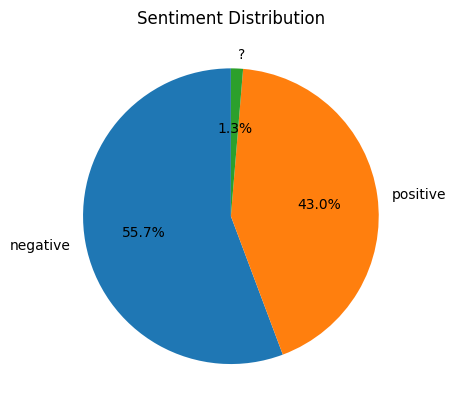

In [ ]:
print(df['sentiment'].value_counts(normalize=True) * 100 )#check if the data is balanced

df['sentiment'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    title='Sentiment Distribution'
)
plt.ylabel('')  # remove y-axis label
plt.show()

Empty Data

In [ ]:
df.replace('?', np.nan, inplace=True) #replace all the '?' to nan
df.isna().mean() * 100 #find all the empty fields

,0
id,0.0000
text,0.0000
sentiment,1.3175
type,0.0000
post_datetime,1.2675
timezone,1.2675
post_likes,1.2150
posts_retweets,1.2150
embedded_content_url,76.8925
username,1.2000


Type Distribution

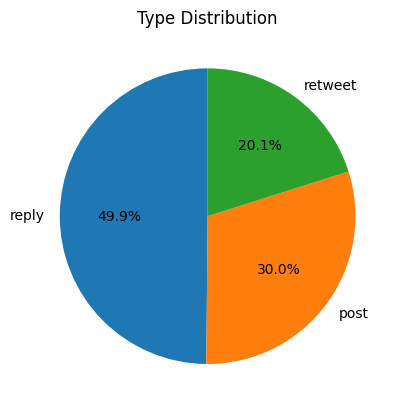

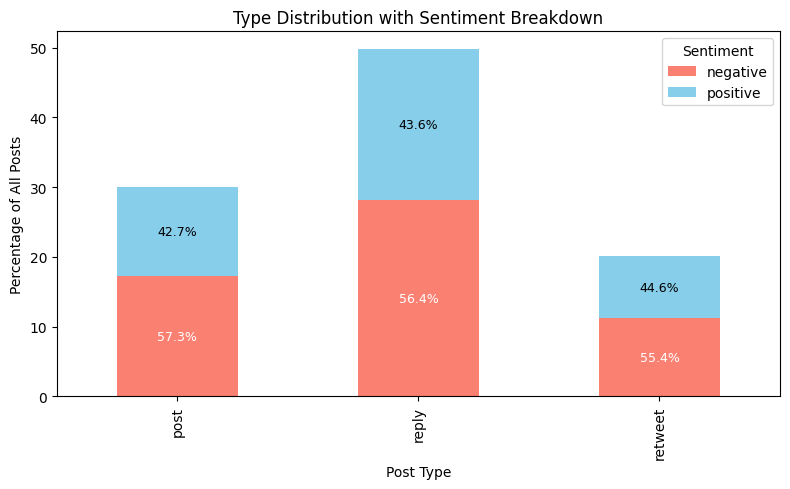

In [ ]:
df['type'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    title='Type Distribution'
)
plt.ylabel('')  # remove y-axis label
plt.show()



type_sentiment_counts = pd.crosstab(df['type'], df['sentiment'])
type_totals = type_sentiment_counts.sum(axis=1)
type_pct = type_sentiment_counts.div(type_totals, axis=0)
type_height = type_pct.mul(type_totals / type_totals.sum(), axis=0) * 100


ax = type_height.plot(
    kind='bar',
    stacked=True,
    color=['salmon', 'skyblue'],
    figsize=(8, 5),
    title='Type Distribution with Sentiment Breakdown'
)

plt.xlabel('Post Type')
plt.ylabel('Percentage of All Posts')
plt.legend(title='Sentiment')
plt.tight_layout()

for i, t in enumerate(type_height.index):
    pos = type_pct.loc[t, 'positive'] * 100
    neg = type_pct.loc[t, 'negative'] * 100
    neg_rect, pos_rect = ax.containers[0][i], ax.containers[1][i]
    ax.text(neg_rect.get_x() + neg_rect.get_width()/2,
            neg_rect.get_y() + neg_rect.get_height()/2,
            f'{neg:.1f}%', ha='center', va='center', color='white', fontsize=9)
    ax.text(pos_rect.get_x() + pos_rect.get_width()/2,
            pos_rect.get_y() + pos_rect.get_height()/2,
            f'{pos:.1f}%', ha='center', va='center', color='black', fontsize=9)

plt.show()

Timezone Distribution

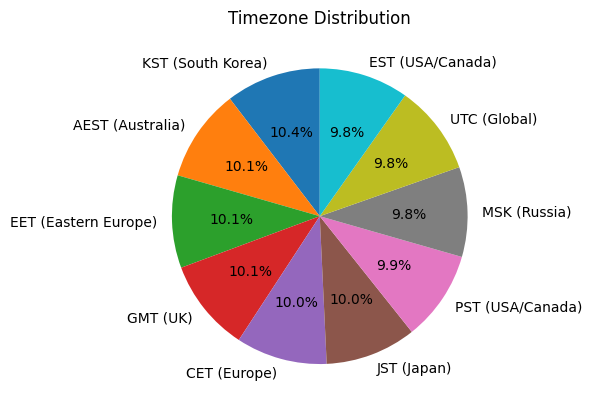

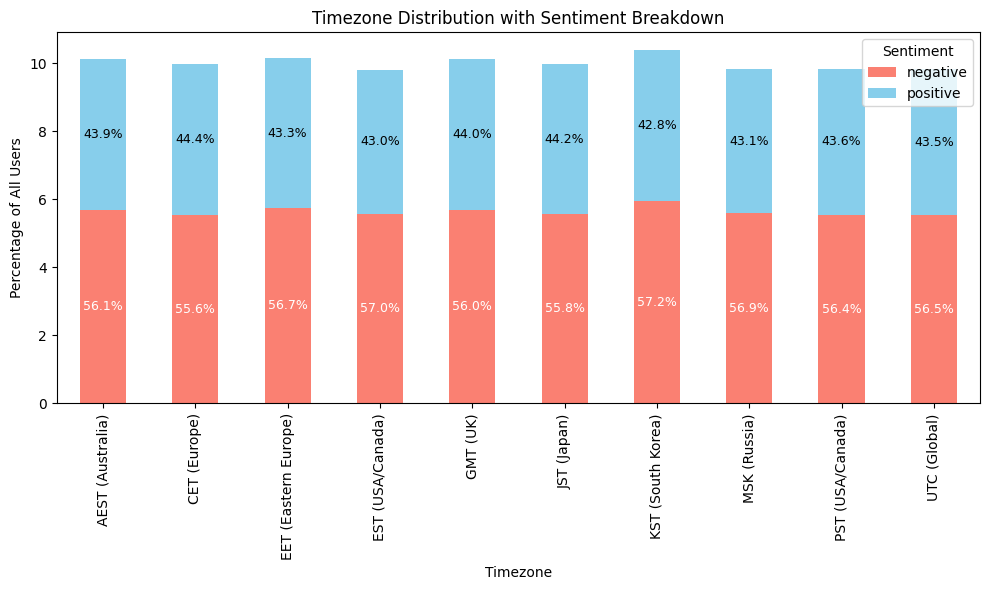

In [ ]:
timezone_labels = {
    'UTC': 'UTC (Global)',
    'EST': 'EST (USA/Canada)',
    'PST': 'PST (USA/Canada)',
    'CET': 'CET (Europe)',
    'EET': 'EET (Eastern Europe)',
    'MSK': 'MSK (Russia)',
    'GMT': 'GMT (UK)',
    'AEST': 'AEST (Australia)',
    'KST': 'KST (South Korea)',
    'JST': 'JST (Japan)'
}

counts = df['timezone'].value_counts()
labels = [timezone_labels.get(tz, tz) for tz in counts.index]

counts.plot(
    kind='pie',
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    title='Timezone Distribution'
)
plt.ylabel('')
plt.show()


#timezones names
timezone_labels = {
    'UTC': 'UTC (Global)',
    'EST': 'EST (USA/Canada)',
    'PST': 'PST (USA/Canada)',
    'CET': 'CET (Europe)',
    'EET': 'EET (Eastern Europe)',
    'MSK': 'MSK (Russia)',
    'GMT': 'GMT (UK)',
    'AEST': 'AEST (Australia)',
    'KST': 'KST (South Korea)',
    'JST': 'JST (Japan)'
}


tz_sentiment_counts = pd.crosstab(df['timezone'], df['sentiment'])
tz_sentiment_counts = tz_sentiment_counts.loc[tz_sentiment_counts.index.isin(timezone_labels.keys())]
tz_sentiment_counts.index = tz_sentiment_counts.index.map(timezone_labels)
tz_totals = tz_sentiment_counts.sum(axis=1)
tz_pct = tz_sentiment_counts.div(tz_totals, axis=0)
tz_height = tz_pct.mul(tz_totals / tz_totals.sum(), axis=0) * 100


ax = tz_height.plot(
    kind='bar',
    stacked=True,
    color=['salmon', 'skyblue'],
    figsize=(10, 6),
    title='Timezone Distribution with Sentiment Breakdown'
)

plt.xlabel('Timezone')
plt.ylabel('Percentage of All Users')
plt.legend(title='Sentiment')
plt.tight_layout()

for i, tz in enumerate(tz_height.index):
    pos = tz_pct.loc[tz, 'positive'] * 100
    neg = tz_pct.loc[tz, 'negative'] * 100
    neg_rect, pos_rect = ax.containers[0][i], ax.containers[1][i]
    ax.text(neg_rect.get_x() + neg_rect.get_width()/2,
            neg_rect.get_y() + neg_rect.get_height()/2,
            f'{neg:.1f}%', ha='center', va='center', color='white', fontsize=9)
    ax.text(pos_rect.get_x() + pos_rect.get_width()/2,
            pos_rect.get_y() + pos_rect.get_height()/2,
            f'{pos:.1f}%', ha='center', va='center', color='black', fontsize=9)

plt.show()

Distribution by Posting Year

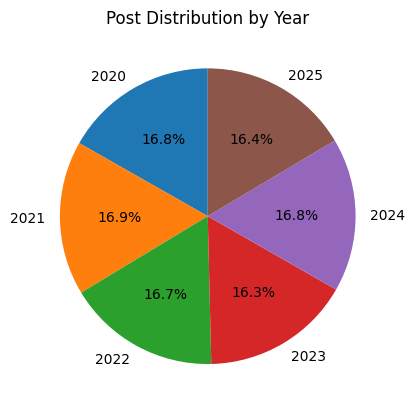

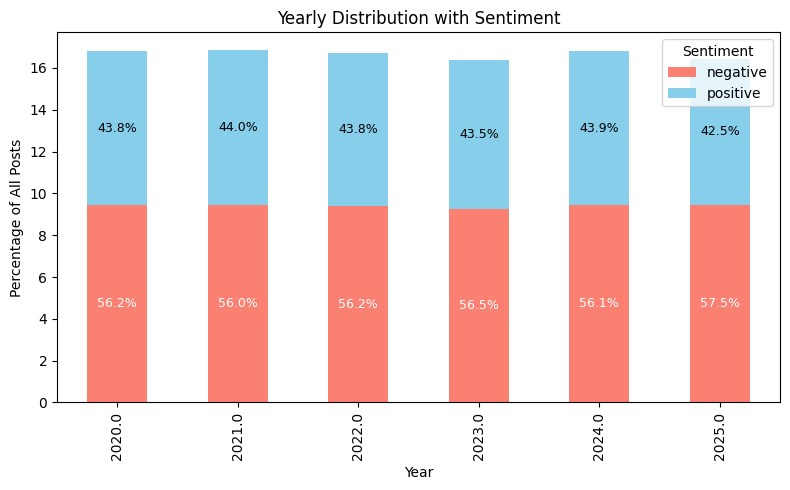

In [ ]:
df['post_datetime'] = pd.to_datetime(df['post_datetime']) #convert to date_time type
df['year'] = df['post_datetime'].dt.year

# Count posts per year
year_counts = df['year'].value_counts().sort_index()

# Convert everything to strings
labels = [str(int(year)) for year in year_counts.index]

plt.pie(
    year_counts.values,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Post Distribution by Year')
plt.ylabel('')
plt.show()


#Sentiment Distribution by Posting Year

# Raw counts by year and sentiment
year_sentiment_counts = pd.crosstab(df['year'], df['sentiment'])

# Calculate total posts per year and normalize for % within each year
year_totals = year_sentiment_counts.sum(axis=1)
year_pct = year_sentiment_counts.div(year_totals, axis=0)  # % within each year

# Calculate height of each bar relative to all posts
year_height = year_pct.mul(year_totals / year_totals.sum(), axis=0) * 100  # final height

# Plot
ax = year_height.plot(
    kind='bar',
    stacked=True,
    color=['salmon', 'skyblue'],
    figsize=(8, 5),
    title='Yearly Distribution with Sentiment'
)

plt.xlabel('Year')
plt.ylabel('Percentage of All Posts')
plt.legend(title='Sentiment')
plt.tight_layout()

# Add % labels inside bars
for i, year in enumerate(year_height.index):
    pos = year_pct.loc[year, 'positive'] * 100 if 'positive' in year_pct.columns else 0
    neg = year_pct.loc[year, 'negative'] * 100 if 'negative' in year_pct.columns else 0

    neg_rect = ax.containers[0][i]
    ax.text(neg_rect.get_x() + neg_rect.get_width()/2,
            neg_rect.get_y() + neg_rect.get_height()/2,
            f'{neg:.1f}%', ha='center', va='center', color='white', fontsize=9)

    if len(ax.containers) > 1:
        pos_rect = ax.containers[1][i]
        ax.text(pos_rect.get_x() + pos_rect.get_width()/2,
                pos_rect.get_y() + pos_rect.get_height()/2,
                f'{pos:.1f}%', ha='center', va='center', color='black', fontsize=9)

plt.show()




checkmark Distribution

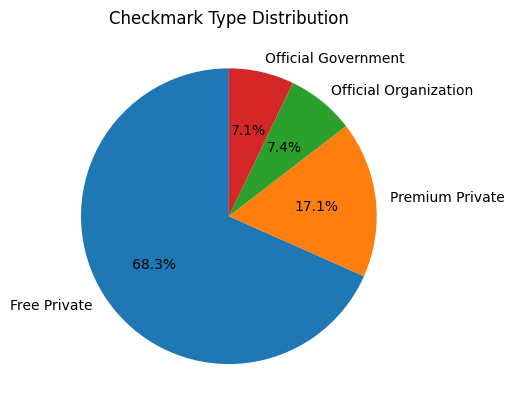

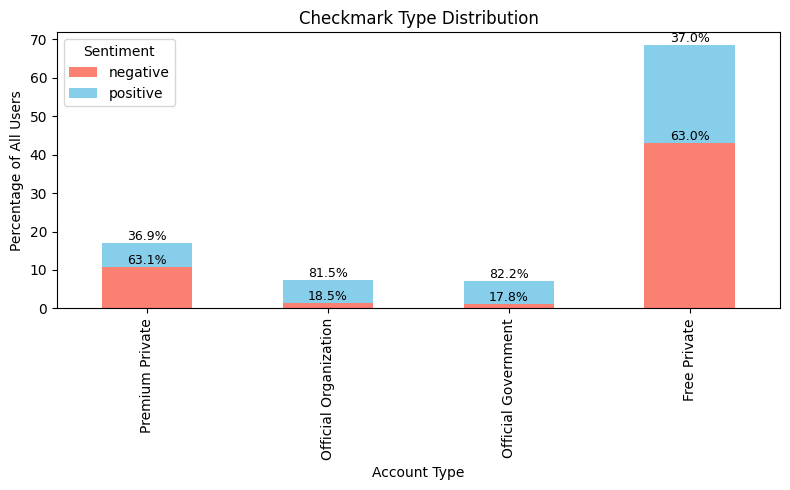

In [ ]:
checkmark_labels = {
    'none': 'Free Private',
    'blue': 'Premium Private',
    'gold': 'Official Organization',
    'grey': 'Official Government'
}

counts = df['checkmark'].value_counts()
labels = [checkmark_labels.get(c, c) for c in counts.index]

counts.plot(
    kind='pie',
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    title='Checkmark Type Distribution'
)
plt.ylabel('')
plt.show()


#Checkmark Type Distribution by Sentiment

checkmark_labels = {
    'none': 'Free Private',
    'blue': 'Premium Private',
    'gold': 'Official Organization',
    'grey': 'Official Government'
}


checkmark_sentiment_counts = pd.crosstab(df['checkmark'], df['sentiment'])
checkmark_sentiment_counts.index = checkmark_sentiment_counts.index.map(checkmark_labels)
checkmark_totals = checkmark_sentiment_counts.sum(axis=1)
checkmark_pct = checkmark_sentiment_counts.div(checkmark_totals, axis=0)
checkmark_height = checkmark_pct.mul(checkmark_totals / checkmark_totals.sum(), axis=0) * 100

# plot
ax = checkmark_height.plot(
    kind='bar',
    stacked=True,
    color=['salmon', 'skyblue'],
    figsize=(8, 5),
    title='Checkmark Type Distribution'
)

plt.xlabel('Account Type')
plt.ylabel('Percentage of All Users')
plt.legend(title='Sentiment')
plt.tight_layout()


for i, t in enumerate(checkmark_height.index):
    pos = checkmark_pct.loc[t, 'positive'] * 100
    neg = checkmark_pct.loc[t, 'negative'] * 100
    neg_rect, pos_rect = ax.containers[0][i], ax.containers[1][i]
    ax.text(neg_rect.get_x() + neg_rect.get_width()/2,
            neg_rect.get_y() + neg_rect.get_height() +0.01,
            f'{neg:.1f}%', ha='center', va='bottom', color='black', fontsize=9)
    ax.text(pos_rect.get_x() + pos_rect.get_width()/2,
            pos_rect.get_y() + pos_rect.get_height()+0.01,
            f'{pos:.1f}%', ha='center', va='bottom', color='black', fontsize=9)

plt.show()

Age Distribution

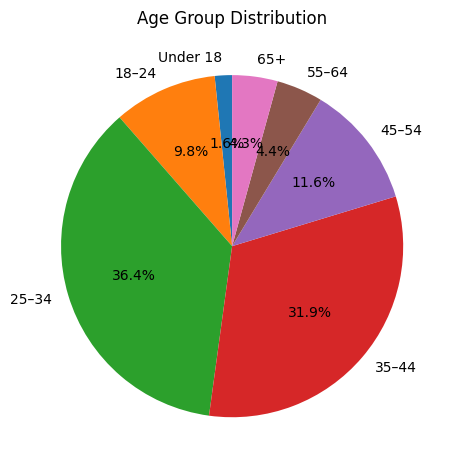

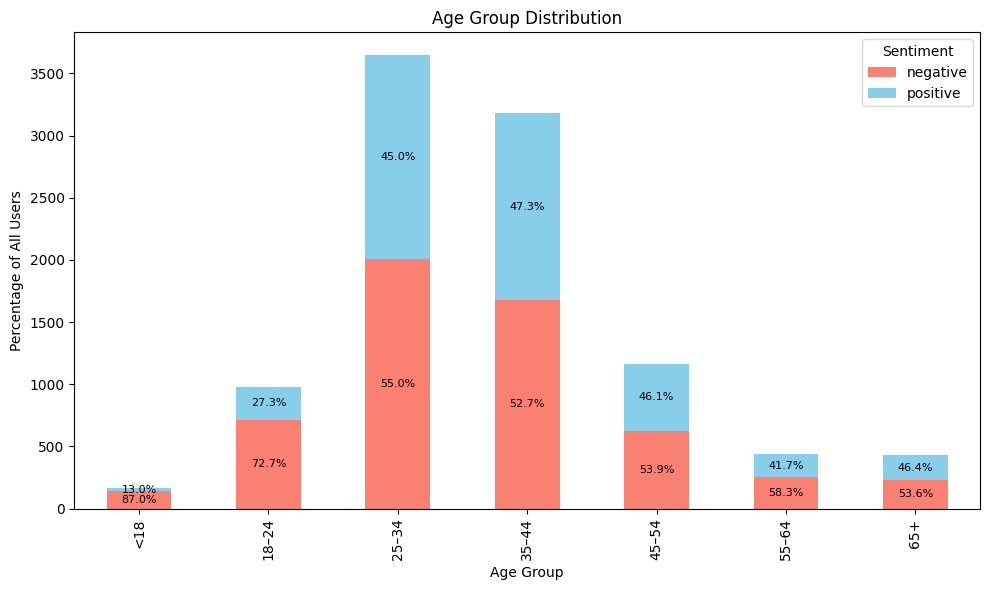

In [ ]:
# Calculate age
df['birthday'] = pd.to_datetime(df['birthday'], errors='coerce')
today = pd.Timestamp.today()
df['age'] = (today - df['birthday']).dt.days // 365

# Define age bins and labels (from image)
bins = [0, 18, 25, 35, 45, 55, 65, 120]
labels = ['Under 18', '18–24', '25–34', '35–44', '45–54', '55–64', '65+']
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels, right=False)

# Pie Chart: Age Group Distribution
df['age_group'].value_counts().sort_index().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    title='Age Group Distribution'
)
plt.ylabel('')
plt.tight_layout()
plt.show()


bins   = [0, 18, 25, 35, 45, 55, 65, 120]
labels = ['<18', '18–24', '25–34', '35–44', '45–54', '55–64', '65+']
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels, right=False)

age_sent_cnt = pd.crosstab(df['age_group'], df['sentiment'])         # absolute counts
group_totals = age_sent_cnt.sum(axis=1)                              # total posts per age group
pop_share    = group_totals / group_totals.sum()                     # share of population
within_pct   = age_sent_cnt.div(group_totals, axis=0) * 100          # % pos/neg in each group

# multiply population share by within‑group ratios
stack_height = within_pct.mul(pop_share, axis=0) * 100               # % of total pop.

#plot
ax = stack_height.plot(kind='bar',
                       stacked=True,
                       color=['salmon', 'skyblue'],
                       figsize=(10,6),
                       title='Age Group Distribution')

plt.xlabel('Age Group')
plt.ylabel('Percentage of All Users')
plt.legend(title='Sentiment')
plt.tight_layout()

# labels should show the within‑group sentiment %, not the bar height
for idx, age_grp in enumerate(stack_height.index):
    pos_pct = within_pct.loc[age_grp, 'positive']
    neg_pct = within_pct.loc[age_grp, 'negative']
    # get bar segment rectangles (negative first, then positive)
    neg_rect, pos_rect = ax.containers[0][idx], ax.containers[1][idx]
    ax.text(neg_rect.get_x() + neg_rect.get_width()/2,
            neg_rect.get_y() + neg_rect.get_height()/2,
            f'{neg_pct:.1f}%', ha='center', va='center', fontsize=8, color='black')
    ax.text(pos_rect.get_x() + pos_rect.get_width()/2,
            pos_rect.get_y() + pos_rect.get_height()/2,
            f'{pos_pct:.1f}%', ha='center', va='center', fontsize=8, color='black')

plt.show()


In [ ]:
numeric_columns_expected = [    #save the numric varible
    'post_likes',
    'posts_retweets',
    'followers',
    'previous_posts_count'
]

for col in numeric_columns_expected:   #change the numeric varible from string to int/float
    df[col] = pd.to_numeric(df[col], errors='coerce')  #If a value cannot be converted ( '?'),  replaced to NaN  instead of raising an error.

df.dtypes

,0
id,object
text,object
sentiment,object
type,object
post_datetime,datetime64[ns]
timezone,object
post_likes,float64
posts_retweets,float64
embedded_content_url,object
username,object


Time of the Day Distribution

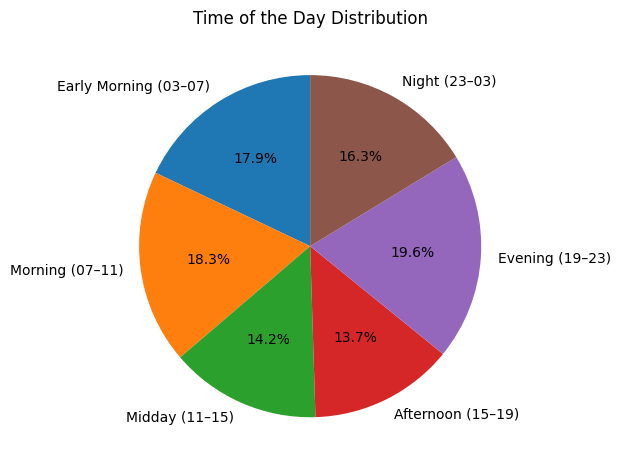

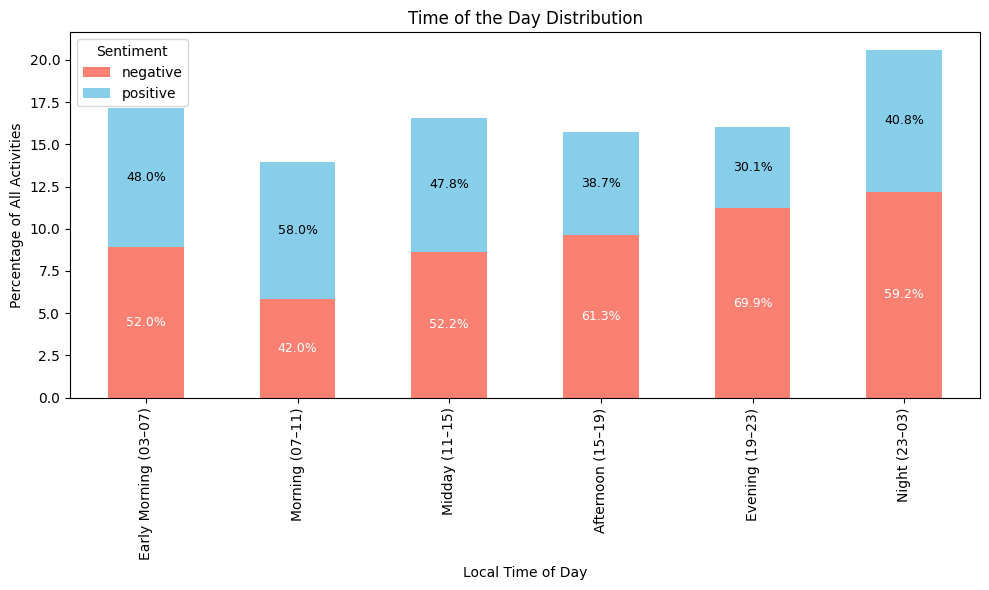

In [ ]:
df['hour'] = df['post_datetime'].dt.hour

def get_day_period(hour):
    if 3 <= hour < 7:
        return 'Early Morning (03–07)'
    elif 7 <= hour < 11:
        return 'Morning (07–11)'
    elif 11 <= hour < 15:
        return 'Midday (11–15)'
    elif 15 <= hour < 19:
        return 'Afternoon (15–19)'
    elif 19 <= hour < 23:
        return 'Evening (19–23)'
    else:
        return 'Night (23–03)'

df['day_period'] = df['hour'].apply(get_day_period)

# pie chart
df['day_period'].value_counts().reindex([
    'Early Morning (03–07)', 'Morning (07–11)', 'Midday (11–15)',
    'Afternoon (15–19)', 'Evening (19–23)', 'Night (23–03)'
]).plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    title='Time of the Day Distribution'
)
plt.ylabel('')
plt.tight_layout()
plt.show()

#convert to timezone
tz_offset = {
    'UTC':  0,  'GMT':  0,
    'EST': -5, 'PST': -8,
    'CET': +1, 'EET': +2, 'MSK': +3,
    'AEST': +10, 'KST': +9, 'JST': +9
}

offset_hours = df['timezone'].map(tz_offset).fillna(0)          # NaN → 0 h
df['_local_dt']   = df['post_datetime'] + pd.to_timedelta(offset_hours, unit='h')
df['local_hour'] = df['_local_dt'].dt.hour

def day_period(h):
    if 3 <= h < 7:   return 'Early Morning (03–07)'
    if 7 <= h < 11:  return 'Morning (07–11)'
    if 11 <= h < 15: return 'Midday (11–15)'
    if 15 <= h < 19: return 'Afternoon (15–19)'
    if 19 <= h < 23: return 'Evening (19–23)'
    return 'Night (23–03)'

df['_period'] = df['local_hour'].apply(day_period)

order = ['Early Morning (03–07)', 'Morning (07–11)', 'Midday (11–15)',
         'Afternoon (15–19)', 'Evening (19–23)', 'Night (23–03)']

period_sent_cnt = pd.crosstab(df['_period'], df['sentiment']).reindex(order)

tot_per_period = period_sent_cnt.sum(axis=1)
share_of_pop   = tot_per_period / tot_per_period.sum()          # bar height
within_pct     = period_sent_cnt.div(tot_per_period, axis=0)    # pos/neg inside bar
stack_height   = within_pct.mul(share_of_pop, axis=0) * 100     # final %

# plot
ax = stack_height.plot(kind='bar', stacked=True,
                       color=['salmon', 'skyblue'],
                       figsize=(10,6),
                       title='Time of the Day Distribution')

plt.xlabel('Local Time of Day')
plt.ylabel('Percentage of All Activities')
plt.legend(title='Sentiment')
plt.tight_layout()

# labels show within‑slot sentiment %
for i, p in enumerate(order):
    pos_pct = within_pct.loc[p, 'positive'] * 100
    neg_pct = within_pct.loc[p, 'negative'] * 100
    neg_rect, pos_rect = ax.containers[0][i], ax.containers[1][i]
    ax.text(neg_rect.get_x()+neg_rect.get_width()/2,
            neg_rect.get_y()+neg_rect.get_height()/2,
            f'{neg_pct:.1f}%', ha='center', va='center', fontsize=9, color='white')
    ax.text(pos_rect.get_x()+pos_rect.get_width()/2,
            pos_rect.get_y()+pos_rect.get_height()/2,
            f'{pos_pct:.1f}%', ha='center', va='center', fontsize=9, color='black')

plt.show()


Previous Posts Distribution by Sentiment

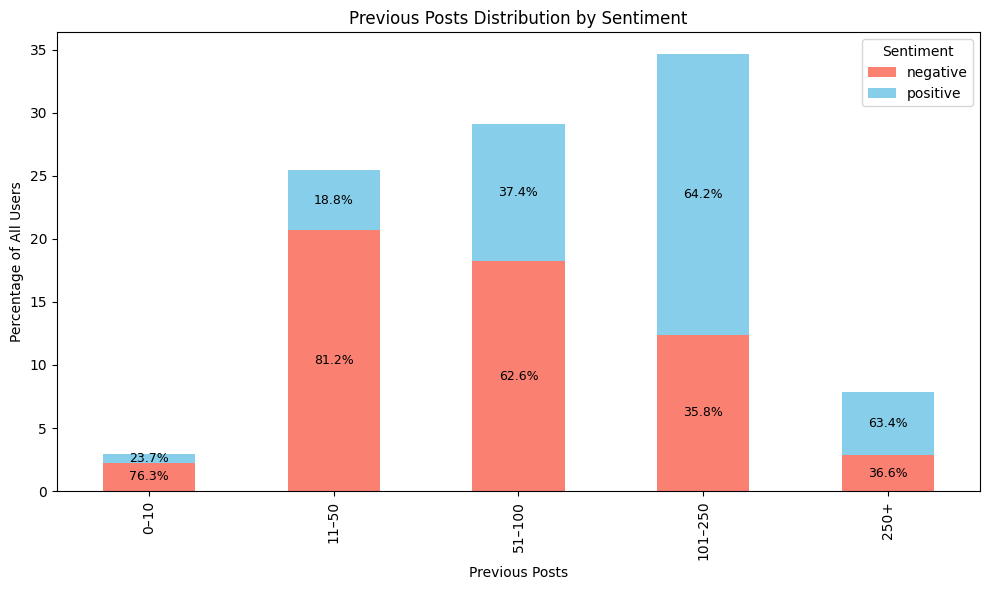

In [ ]:
# Define your custom bins
df['posts_bin'] = pd.cut(df['previous_posts_count'],
    bins=[0, 10, 50, 100, 250, float('inf')],
    labels=['0–10', '11–50', '51–100', '101–250', '250+']
)

# Sentiment counts and normalization
sent_bin = pd.crosstab(df['posts_bin'], df['sentiment'])
group_totals = sent_bin.sum(axis=1)
share_of_total = group_totals / group_totals.sum()
within_group_pct = sent_bin.div(group_totals, axis=0)
final_vals = within_group_pct.mul(share_of_total, axis=0) * 100

# Plot
ax = final_vals.plot(kind='bar', stacked=True, color=['salmon', 'skyblue'],
                     figsize=(10,6), title='Previous Posts Distribution by Sentiment')

plt.xlabel('Previous Posts')
plt.ylabel('Percentage of All Users')
plt.legend(title='Sentiment')
plt.tight_layout()

# Add sentiment % labels within each bar
for i, group in enumerate(final_vals.index):
    pos = within_group_pct.loc[group, 'positive'] * 100
    neg = within_group_pct.loc[group, 'negative'] * 100
    neg_rect, pos_rect = ax.containers[0][i], ax.containers[1][i]

    ax.text(neg_rect.get_x() + neg_rect.get_width()/2,
            neg_rect.get_y() + neg_rect.get_height()/2,
            f'{neg:.1f}%', ha='center', va='center', fontsize=9, color='black')
    ax.text(pos_rect.get_x() + pos_rect.get_width()/2,
            pos_rect.get_y() + pos_rect.get_height()/2,
            f'{pos:.1f}%', ha='center', va='center', fontsize=9, color='black')

plt.show()


Post likes, Post Retweets, Followers

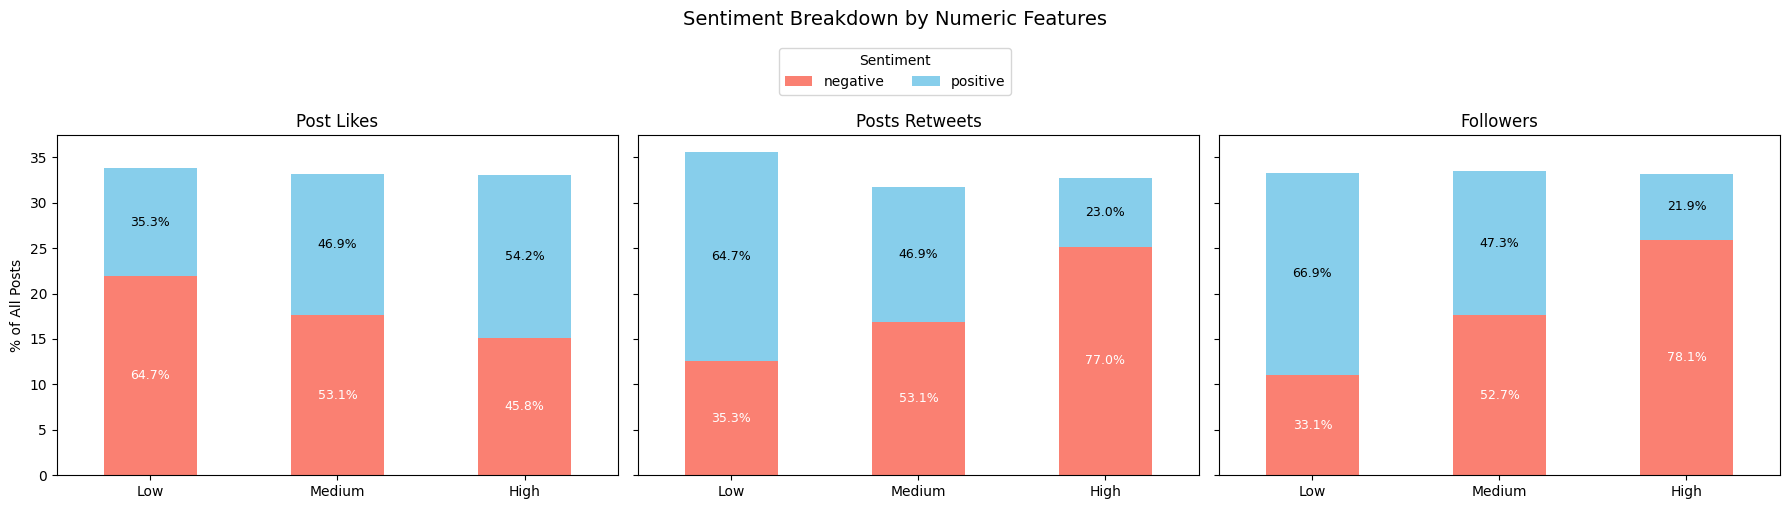

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Numeric features you want to analyse
numeric_fields = ['post_likes', 'posts_retweets', 'followers']
sentiment_col  = 'sentiment'          # positive / negative
bin_labels     = ['Low', 'Medium', 'High']
sent_colors    = {'negative': 'salmon', 'positive': 'skyblue'}

# ── 1.  Trim each feature to its central 95 %  ──────────────────────
df_trim = df.copy()
for col in numeric_fields:
    lo, hi = df_trim[col].quantile([0.025, 0.975])
    df_trim = df_trim[(df_trim[col] >= lo) & (df_trim[col] <= hi)]

# ── 2.  Build the figure: ONE row, three columns  ───────────────────
fig, axes = plt.subplots(1, len(numeric_fields),
                         figsize=(18, 4.5),
                         sharey=True)

for ax, field in zip(axes, numeric_fields):
    # 2a.  Tercile bins (Low / Medium / High)
    df_trim[field + '_bin'] = pd.qcut(df_trim[field],
                                      q=3,
                                      labels=bin_labels,
                                      duplicates='drop')

    # 2b.  Sentiment distribution
    counts     = pd.crosstab(df_trim[field + '_bin'], df_trim[sentiment_col])
    totals     = counts.sum(axis=1)
    pct_inside = counts.div(totals, axis=0)                     # % within bin
    bar_height = pct_inside.mul(totals / totals.sum(), axis=0) * 100  # bar height

    # 2c.  Plot stacked bar
    bar_height.plot(kind='bar',
                    stacked=True,
                    color=[sent_colors.get(c) for c in counts.columns],
                    ax=ax, legend=False)

    ax.set_title(field.replace('_', ' ').title())
    ax.set_xlabel('')
    ax.set_xticklabels(bar_height.index, rotation=0)
    ax.set_ylabel('% of All Posts' if ax is axes[0] else '')  # show y-label once

    # 2d.  Add in-bar percentage labels
    for i, label in enumerate(bar_height.index):
        neg_pct = pct_inside.loc[label, 'negative'] * 100 if 'negative' in pct_inside else 0
        pos_pct = pct_inside.loc[label, 'positive'] * 100 if 'positive' in pct_inside else 0

        neg_rect = ax.containers[0][i]
        ax.text(neg_rect.get_x() + neg_rect.get_width()/2,
                neg_rect.get_y() + neg_rect.get_height()/2,
                f'{neg_pct:.1f}%',
                ha='center', va='center', color='white', fontsize=9)

        if len(ax.containers) > 1:
            pos_rect = ax.containers[1][i]
            ax.text(pos_rect.get_x() + pos_rect.get_width()/2,
                    pos_rect.get_y() + pos_rect.get_height()/2,
                    f'{pos_pct:.1f}%',
                    ha='center', va='center', color='black', fontsize=9)

# ── 3.  Global legend & layout  ─────────────────────────────────────
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title='Sentiment',
           loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.05))

fig.suptitle('Sentiment Breakdown by Numeric Features',
             fontsize=14, y=1.12)
plt.tight_layout(rect=[0, 0, 1, 1])
plt.show()


<ipython-input-15-a2ced7980e0a>:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
<ipython-input-15-a2ced7980e0a>:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
<ipython-input-15-a2ced7980e0a>:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


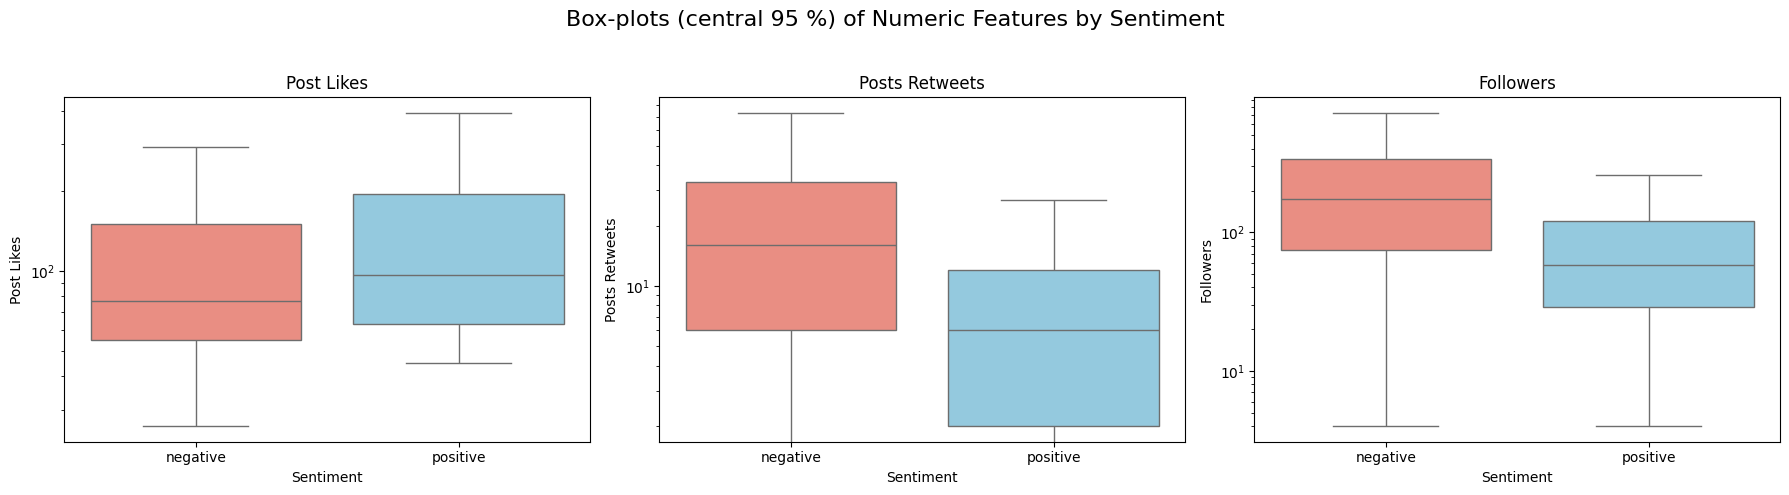

In [ ]:

import seaborn as sns

numeric_fields = ['post_likes', 'posts_retweets', 'followers']

# ── 1.  Remove extreme 2.5 % tails (per feature) ─────────────────────
df_trim = df.copy()

for col in numeric_fields:
    low_q, high_q = df[col].quantile([0.025, 0.975])
    df_trim = df_trim[(df_trim[col] >= low_q) & (df_trim[col] <= high_q)]

# ── 2.  Build the box-plots ──────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)

for ax, field in zip(axes, numeric_fields):
    sns.boxplot(
        data=df_trim,
        x='sentiment',
        y=field,
        palette={'positive': 'skyblue', 'negative': 'salmon'},
        ax=ax,
        showfliers=False          # whiskers stop at 1.5×IQR
    )

    ax.set_yscale('log')          # comment-out if you prefer linear scale
    ax.set_title(field.replace('_', ' ').title())
    ax.set_xlabel('Sentiment')
    ax.set_ylabel(field.replace('_', ' ').title())

fig.suptitle('Box-plots (central 95 %) of Numeric Features by Sentiment', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


Correlation Matrix

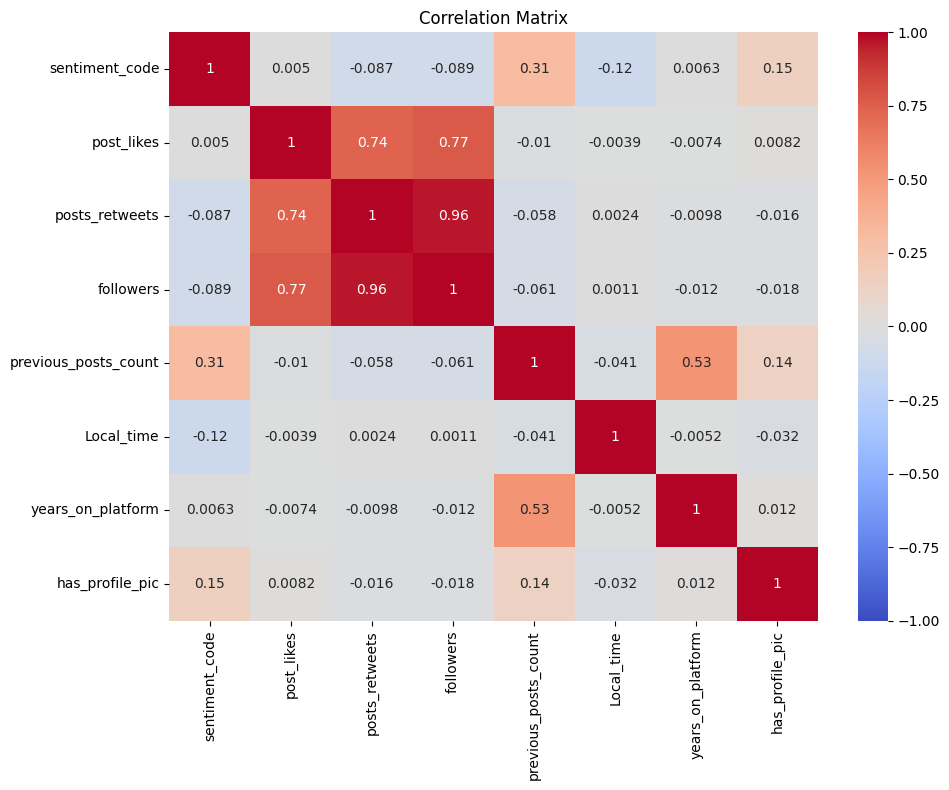

In [ ]:

import seaborn as sns

# 2. Create binary column for profile picture
df['has_profile_pic'] = df['profile_picture'].notna() & df['profile_picture'].str.strip().ne('')
df['has_profile_pic'] = df['has_profile_pic'].astype(int)  # Convert to 0/1


# 1. Convert sentiment to numeric
df['sentiment_code'] = df['sentiment'].map({'negative': 0, 'positive': 1})

df['Local_time'] = df['local_hour'].apply(lambda h: h + 24 if h < 3 else h)
# 3. Calculate years on platform from account creation date
df['account_creation_date'] = pd.to_datetime(df['account_creation_date'], errors='coerce')
df['years_on_platform'] = (today - df['account_creation_date']).dt.days // 365

# 4. Select columns for correlation
cols = [
    'sentiment_code',
    'post_likes',
    'posts_retweets',
    'followers',
    'previous_posts_count',
    'Local_time',
    'years_on_platform',
    'has_profile_pic'
]

# 5. Drop rows with missing values in selected columns
df_corr = df[cols].dropna()

# 6. Compute correlation matrix
corr = df_corr.corr()

# 7. Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()


Top hashtags in posts

In [ ]:
# Extract list of hashtags from each text
df['hashtags'] = df['text'].str.findall(r'#\w+')

from collections import Counter

positive_hashtags = df[df['sentiment'] == 'positive']['hashtags'].explode().dropna()
negative_hashtags = df[df['sentiment'] == 'negative']['hashtags'].explode().dropna()

# count the mose sommmon hashtags in each sentiment
top_pos_tags = Counter(positive_hashtags).most_common(15)
top_neg_tags = Counter(negative_hashtags).most_common(15)

print("Top hashtags in positive posts:")
for tag, count in top_pos_tags:
    print(f"{tag}: {count}")

print("\n Top hashtags in negative posts:")
for tag, count in top_neg_tags:
    print(f"{tag}: {count}")


Top hashtags in positive posts:
#MentalHealthAwareness: 499
#PositiveVibes: 498
#SelfCare: 429
#Gratitude: 359
#ConfidenceBoost: 293
#PersonalGrowth: 292
#MentalHealthMatters: 248
#MentalHealth: 210
#Empowerment: 184
#NewBeginnings: 179
#Appreciation: 153
#SelfDiscovery: 148
#EmotionalIntelligence: 137
#InnerPeace: 134
#EnergyBoost: 124

 Top hashtags in negative posts:
#MentalHealthAwareness: 491
#SelfCare: 148
#MentalHealthMatters: 122
#AnxietyRelief: 104
#MentalHealth: 103
#MentalHealthStruggles: 99
#Heartbreak: 80
#Anxiety: 69
#AngerManagement: 69
#SelfDoubt: 65
#EmotionalIntelligence: 59
#EmotionalPain: 51
#Uncertainty: 50
#FeelingOverwhelmed: 50
#FeelingLost: 50


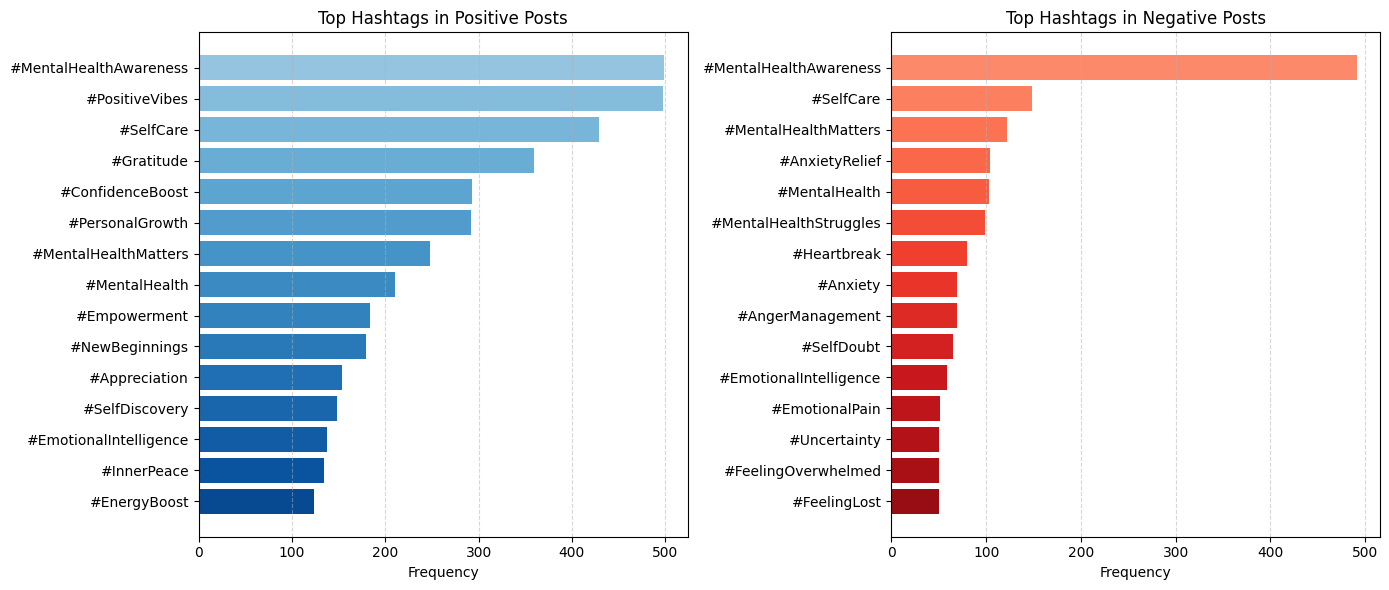

In [ ]:
from collections import Counter
import matplotlib.cm as cm

# Step 1: Extract hashtags
df['hashtags'] = df['text'].str.findall(r'#\w+')

# Step 2: Explode and filter by sentiment
positive_tags = df[df['sentiment'] == 'positive']['hashtags'].explode().dropna()
negative_tags = df[df['sentiment'] == 'negative']['hashtags'].explode().dropna()

# Step 3: Count most common hashtags
top_pos = Counter(positive_tags).most_common(15)
top_neg = Counter(negative_tags).most_common(15)

# Step 4: Separate hashtags and counts
pos_tags, pos_counts = zip(*top_pos) if top_pos else ([], [])
neg_tags, neg_counts = zip(*top_neg) if top_neg else ([], [])

# Step 5: Generate colors
pos_colors = cm.Blues(np.linspace(0.4, 0.9, len(pos_counts)))
neg_colors = cm.Reds(np.linspace(0.4, 0.9, len(neg_counts)))

# Step 6: Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Positive hashtags
axes[0].barh(pos_tags[::-1], pos_counts[::-1], color=pos_colors[::-1])
axes[0].set_title('Top Hashtags in Positive Posts')
axes[0].set_xlabel('Frequency')
axes[0].grid(True, axis='x', linestyle='--', alpha=0.5)

# Negative hashtags
axes[1].barh(neg_tags[::-1], neg_counts[::-1], color=neg_colors[::-1])
axes[1].set_title('Top Hashtags in Negative Posts')
axes[1].set_xlabel('Frequency')
axes[1].grid(True, axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


<ipython-input-19-60bb4fb94cd0>:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=avg_hashtags.index, y=avg_hashtags.values, palette=['salmon', 'skyblue'])


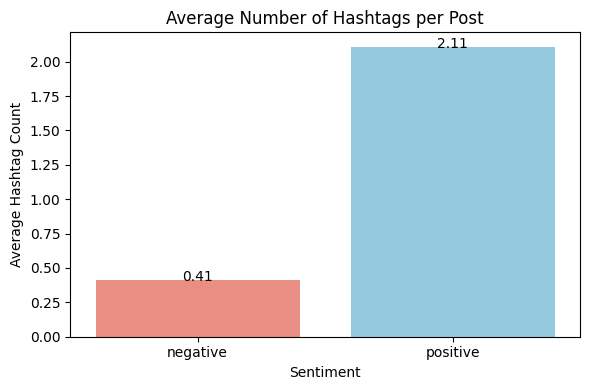

In [ ]:
# Step 2: Count number of hashtags per post
df['hashtag_count'] = df['hashtags'].apply(len)

# Step 3: Calculate average number of hashtags per sentiment
avg_hashtags = df.groupby('sentiment')['hashtag_count'].mean()


# Step 4: Bar plot - average hashtag count
plt.figure(figsize=(6, 4))
ax = sns.barplot(x=avg_hashtags.index, y=avg_hashtags.values, palette=['salmon', 'skyblue'])

# Add value labels
for i, v in enumerate(avg_hashtags.values):
    ax.text(i, v + 0.02, f'{v:.2f}', ha='center', va='center')

plt.title('Average Number of Hashtags per Post')
plt.ylabel('Average Hashtag Count')
plt.xlabel('Sentiment')
plt.tight_layout()
plt.show()



Top Terms- TF-IDF

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
import re

# Clean text: remove hashtags, links, punctuation, lowercasing
def clean(text):
    text = str(text).lower()
    text = re.sub(r'#\w+', '', text)             # remove hashtags
    text = re.sub(r'http\S+|www\S+', '', text)   # remove URLs
    text = re.sub(r'[^a-z\s]', '', text)         # remove punctuation/numbers
    return text.strip()

df['clean_text'] = df['text'].apply(clean)

# Split by sentiment
pos_texts = df[df['sentiment'] == 'positive']['clean_text']
neg_texts = df[df['sentiment'] == 'negative']['clean_text']

# Initialize and fit TF-IDF vectorizer on ALL text to share vocab
vectorizer = TfidfVectorizer(stop_words='english', max_features=10000)
vectorizer.fit(df['clean_text'])

# Transform separately
tfidf_pos = vectorizer.transform(pos_texts)
tfidf_neg = vectorizer.transform(neg_texts)

# Get top terms
def get_top_terms(tfidf_matrix, vectorizer, N=15):
    scores = np.asarray(tfidf_matrix.sum(axis=0)).ravel()
    indices = scores.argsort()[::-1][:N]
    terms = vectorizer.get_feature_names_out()
    return [(terms[i], scores[i]) for i in indices]

top_pos = get_top_terms(tfidf_pos, vectorizer)
top_neg = get_top_terms(tfidf_neg, vectorizer)

# Print results
print(" Top Positive Terms:")
for term, score in top_pos:
    print(f"{term:<20} {score:.3f}")

print("\n Top Negative Terms:")
for term, score in top_neg:
    print(f"{term:<20} {score:.3f}")


 Top Positive Terms:
feel                 1134.750
feeling              689.762
nan                  665.374
like                 502.951
im                   450.821
just                 252.277
really               230.015
time                 192.257
know                 191.399
love                 186.460
want                 172.283
people               154.461
life                 154.235
think                150.454
good                 143.786

 Top Negative Terms:
nan                  1796.663
feel                 1462.427
feeling              1063.274
im                   636.926
like                 632.207
just                 442.999
really               313.569
know                 301.162
little               287.222
time                 253.508
bit                  246.306
ive                  212.419
people               208.638
want                 206.586
dont                 202.995


Average text length by sentiment:
sentiment
negative     97.759345
positive    103.964917
Name: text_length, dtype: float64


<ipython-input-21-d9418e0def63>:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=avg_length.index, y=avg_length.values, palette=['salmon', 'skyblue'])


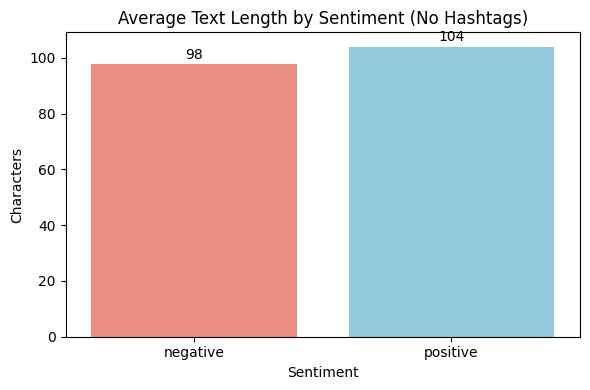

In [ ]:

# Step 1: Remove hashtags from text and calculate text length (in characters)
df['text_no_hashtags'] = df['text'].str.replace(r'#\w+', '', regex=True)
df['text_length'] = df['text_no_hashtags'].str.len()

# Step 2: Average text length by sentiment
avg_length = df.groupby('sentiment')['text_length'].mean()
print("Average text length by sentiment:")
print(avg_length)

# Step 3: Bar plot of average text length
plt.figure(figsize=(6, 4))
ax = sns.barplot(x=avg_length.index, y=avg_length.values, palette=['salmon', 'skyblue'])

# Add value labels
for i, v in enumerate(avg_length.values):
    ax.text(i, v + 2, f'{v:.0f}', ha='center')

plt.title('Average Text Length by Sentiment (No Hashtags)')
plt.ylabel('Characters')
plt.xlabel('Sentiment')
plt.tight_layout()
plt.show()

### Pre-Processing

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pandas.tseries.offsets import DateOffset

from google.colab import files
from google.colab import drive

In [ ]:
drive.mount('/content/drive')

df_path = '/content/drive/MyDrive/למידת מכונה/sentiment.csv'
df = pd.read_csv(df_path)

df.replace('?', np.nan, inplace=True) #replace all the '?' to nan
df.isna().mean() * 100 #find all the empty fields

Mounted at /content/drive


,0
id,0.0000
text,0.0000
sentiment,1.3175
type,0.0000
post_datetime,1.2675
timezone,1.2675
post_likes,1.2150
posts_retweets,1.2150
embedded_content_url,76.8925
username,1.2000


Data Types

In [ ]:
# Convert to datetime
df['post_datetime'] = pd.to_datetime(df['post_datetime'], errors='coerce')
df['birthday'] = pd.to_datetime(df['birthday'], errors='coerce')
df['account_creation_date'] = pd.to_datetime(df['account_creation_date'], errors='coerce')

# Convert to numeric
numeric_cols = [
    'post_likes', 'posts_retweets', 'followers',
    'previous_posts_count'
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Convert sentiment and type to category
df['sentiment'] = df['sentiment'].astype('category')
df['type'] = df['type'].astype('category')
df['checkmark'] = df['checkmark'].astype('category')
df['timezone'] = df['timezone'].astype('category')

#convert text fields like username/text to string
df['username'] = df['username'].astype('string')
df['text'] = df['text'].astype('string')

df.dtypes

,0
id,object
text,string[python]
sentiment,category
type,category
post_datetime,datetime64[ns]
timezone,category
post_likes,float64
posts_retweets,float64
embedded_content_url,object
username,string[python]


Duplicate Records

In [ ]:
#Users with more than one post
user_counts = df['username'].value_counts()
multi_post_users = user_counts[user_counts > 1]

print(f"Users with more than one post: {len(multi_post_users)}")
multi_post_users.head()


Users with more than one post: 1652


,count
username,
@michael_l,8
@john_h,8
@david_m,7
@david_r,6
@john_b,6


In [ ]:
# Sort by user, text, and datetime
df_sorted = df.sort_values(by=['username', 'text', 'post_datetime'])

# Create a shifted datetime per user+text group
df_sorted['prev_post_time'] = df_sorted.groupby(['username', 'text'])['post_datetime'].shift()

# Calculate time difference in seconds
df_sorted['time_diff'] = (df_sorted['post_datetime'] - df_sorted['prev_post_time']).dt.total_seconds()

# Filter where the time diff is less than or equal to 600 seconds
duplicates = df_sorted[df_sorted['time_diff'].between(0, 600)]
print(f"Found {len(duplicates)} duplicate samples by  user, text, and datetime.")

# Find duplicates based on text + datetime
dup_mask = df.duplicated(subset=['text', 'post_datetime'], keep=False)
duplicates_text_time = df[dup_mask]
print(f"Found {len(duplicates_text_time)} posts with the same text and datetime.")

#Sort by Username and text
user_text_type_counts = df.groupby(['username', 'text'])['type'].nunique()
reused_by_user = user_text_type_counts[user_text_type_counts > 1]

print(f"Found {len(reused_by_user)} user-text pairs reused in multiple types.\n")





Found 0 duplicate samples by  user, text, and datetime.
Found 0 posts with the same text and datetime.
Found 0 user-text pairs reused in multiple types.



In [ ]:
#most repeted texts

text_counts = df['text'].value_counts()

print(f"Number of unique texts: {len(text_counts)}")
print("\nMost repeated texts:")
print(text_counts.head(95))


text_sentiment_counts = df.groupby('text')['sentiment'].nunique()

texts_with_mixed_sentiment = text_sentiment_counts[text_sentiment_counts > 1]

print(f"\nFound {len(texts_with_mixed_sentiment)} texts that appear with different sentiments.")
print(texts_with_mixed_sentiment.head())


Number of unique texts: 39905

Most repeated texts:
text
im feeling generous today so lets take him at his word nan                                                                                                                              2
i feel depressed nan                                                                                                                                                                    2
i forgive myself that ive accepted and allowed myself to hold on to the release valve of smoking by thinking about smoking each and every time i feel stressed strained or bored nan    2
i have thought that things were going to be different not long ago but i truly feel more faithful within like a completely different person nan                                         2
i texted the wife and said im gonna come up to the school now cuz im feeling helpless here nan                                                                                          2
             

Missing Data

In [ ]:
from datetime import timedelta
#Sentiment
df = df[df['sentiment'].notna()] #remove records with empty sentiment

#Timezone
df['timezone'] = df['timezone'].fillna('UTC') #missing timezone> UTC
mean_hour_utc = int(df['post_datetime'].dropna().dt.hour.mean()) #calculate the mean time
#Timezone map
tz_offset = {
    'UTC':  0, 'GMT':  0,
    'EST': -5, 'PST': -8,
    'CET': +1, 'EET': +2, 'MSK': +3,
    'AEST': +10, 'KST': +9, 'JST': +9
}

#calculate by local timezone
def generate_datetime_utc(tz):
    offset = tz_offset.get(tz, 0)
    random_days = np.random.randint(0, 365)
    base_date = pd.Timestamp.today().normalize() - pd.Timedelta(days=random_days)
    local_dt = base_date + pd.Timedelta(hours=mean_hour_utc)
    utc_dt = local_dt - pd.Timedelta(hours=offset)
    return utc_dt
missing_mask = df['post_datetime'].isna()
df.loc[missing_mask, 'post_datetime'] = df.loc[missing_mask, 'timezone'].apply(generate_datetime_utc)

#update the local time
offset_hours = df['timezone'].map(tz_offset).fillna(0)
df['local_dt'] = df['post_datetime'] + pd.to_timedelta(offset_hours, unit='h')
df['local_hour'] = df['local_dt'].dt.hour


#age
today = pd.Timestamp.today()
df['age'] = ((today - df['birthday']).dt.days // 365)
mean_age = int(df['age'].dropna().mean())#Calculate average age (in years) from existing birthdays

#Generate random birthdays based on the average age
def generate_random_birthday(avg_age):
    # Add small randomness in days (up to 1 year)
    random_days = np.random.randint(0, 365)
    return today - pd.Timedelta(days=(avg_age * 365 + random_days))

#Fill missing birthday values with random birthday
missing_birthday_mask = df['birthday'].isna()
df.loc[missing_birthday_mask, 'birthday'] = [
    generate_random_birthday(mean_age) for _ in range(missing_birthday_mask.sum())
]

#Recalculate age for all rows (including newly filled)
df['age'] = ((today - df['birthday']).dt.days // 365)


#numeric variables
zero_fill_cols = ['post_likes', 'posts_retweets', 'followers', 'previous_posts_count']
df[zero_fill_cols] = df[zero_fill_cols].fillna(0)

#checkmark
df['checkmark'] = df['checkmark'].fillna('none')

#profile_picture
df['has_profile_pic'] = df['profile_picture'].notna() & df['profile_picture'].str.strip().ne('')
df['has_profile_pic'] = df['has_profile_pic'].astype(int)
#email
df['email'] = df['email'].fillna('').astype(str)
#username
df['username'] = df['username'].fillna('').astype(str)

#account_creation_date, years on platform
today = pd.Timestamp.today()
df['days_on_platform'] = (today - df['account_creation_date']).dt.days
valid_rate_mask = (df['previous_posts_count'].notna()) & (df['days_on_platform'] > 0)

# קצב פוסטים ליום למשתמשים תקינים
df['posting_rate'] = np.nan
df.loc[valid_rate_mask, 'posting_rate'] = df.loc[valid_rate_mask, 'previous_posts_count'] / df.loc[valid_rate_mask, 'days_on_platform']
avg_posts_per_day = df['posting_rate'].mean()

# רשומות עם תאריך פתיחה חסר
missing_mask = df['account_creation_date'].isna()
estimated_days = (df.loc[missing_mask, 'previous_posts_count'] / avg_posts_per_day).clip(lower=30, upper=5*365) #calculate number of days back
df.loc[missing_mask, 'account_creation_date'] = today - pd.to_timedelta(estimated_days, unit='D') #create the account creatain date

#update years_on_platform
df['years_on_platform'] = ((today - df['account_creation_date']).dt.days // 365)


<ipython-input-15-7d547c3553d9>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['timezone'] = df['timezone'].fillna('UTC') #missing timezone> UTC
<ipython-input-15-7d547c3553d9>:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['local_dt'] = df['post_datetime'] + pd.to_timedelta(offset_hours, unit='h')
<ipython-input-15-7d547c3553d9>:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats 

In [ ]:
df.isna().mean() * 100 #find all the empty fields

,0
id,0.000000
text,0.000000
sentiment,0.000000
type,0.000000
post_datetime,0.000000
timezone,0.000000
post_likes,0.000000
posts_retweets,0.000000
embedded_content_url,76.875333
username,0.000000


Catagories

In [ ]:
#ages
df['birthday'] = pd.to_datetime(df['birthday'], errors='coerce')
df['age'] = (pd.Timestamp.today() - df['birthday']).dt.days // 365

bins   = [0, 18, 25, 35, 45, 55, 65, 120]
labels = ['<18', '18–24', '25–34', '35–44', '45–54', '55–64', '65+']
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels, right=False)
#years
df['post_datetime'] = pd.to_datetime(df['post_datetime']) #convert to date_time type
df['year'] = df['post_datetime'].dt.year

#posting time of the day
df['hour'] = df['post_datetime'].dt.hour

def get_day_period(hour):
    if 3 <= hour < 7:
        return 'Early Morning' #(03–07)
    elif 7 <= hour < 11:
        return 'Morning' #(07–11)
    elif 11 <= hour < 15:
        return 'Midday' # (11–15)
    elif 15 <= hour < 19:
        return 'Afternoon' # (15–19)
    elif 19 <= hour < 23:
        return 'Evening' # (19–23)
    else:
        return 'Night' # (23–03)

df['day_period'] = df['hour'].apply(get_day_period)


Segmentation

In [ ]:

# Has Embedded Content
df['has_embedded_content'] = df['embedded_content_url'].notna().astype(int)

# Embedded Content Domain ===
df['embed_domain'] = df['embedded_content_url'].str.extract(r'https?://(?:www\.)?([^/\s]+)')

#Has Profile Picture ===
df['has_profile_picture'] = df['profile_picture'].notna().astype(int)

#Profile Picture Type (basic)
df['profile_pic_type'] = df['profile_picture'].apply(
    lambda x: 'default' if pd.notna(x) and 'default' in x else (
              'custom' if pd.notna(x) else 'none'))

# Check segment distributions
print("Has embedded content:\n", df['has_embedded_content'].value_counts())
print("\nTop embed domains:\n", df['embed_domain'].value_counts().head())
print("\nHas profile picture:\n", df['has_profile_picture'].value_counts())
print("\nProfile pic types:\n", df['profile_pic_type'].value_counts())


Has embedded content:
 has_embedded_content
0    30345
1     9128
Name: count, dtype: int64

Top embed domains:
 embed_domain
assets.storage.net    7446
smith.com               15
brown.com               12
jones.com               12
johnson.com             10
Name: count, dtype: int64

Has profile picture:
 has_profile_picture
1    27350
0    12123
Name: count, dtype: int64

Profile pic types:
 profile_pic_type
custom    27350
none      12123
Name: count, dtype: int64


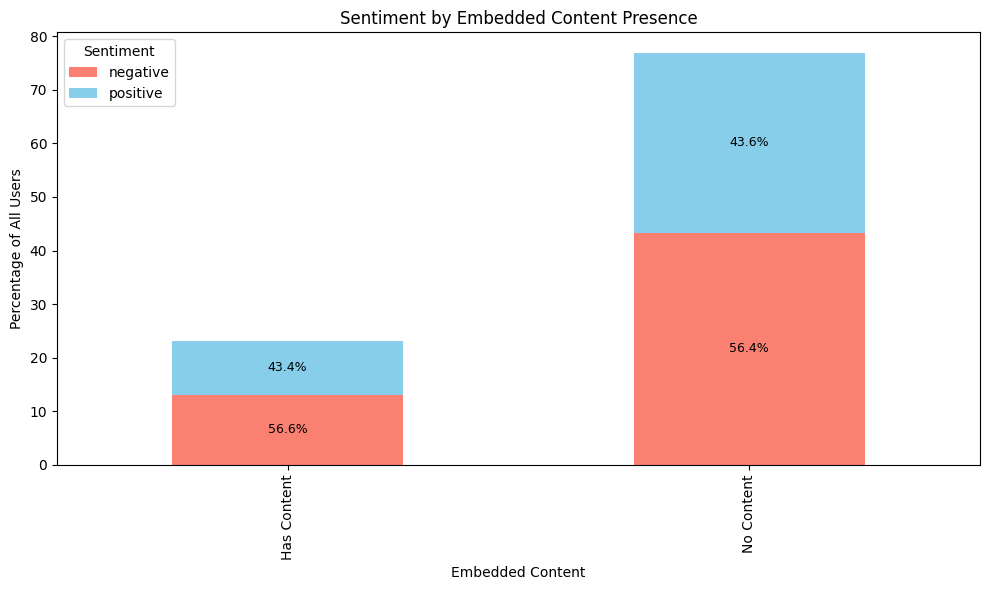

Sentiment Breakdown by Top Embedded Domains:

                    Percent of Users with Content  Percent Negative  \
embed_domain                                                          
assets.storage.net                           99.3              57.0   
brown.com                                     0.2              75.0   
johnson.com                                   0.1              40.0   
jones.com                                     0.2              50.0   
smith.com                                     0.2              46.7   

                    Percent Positive  
embed_domain                          
assets.storage.net              43.0  
brown.com                       25.0  
johnson.com                     60.0  
jones.com                       50.0  
smith.com                       53.3  


In [ ]:
# Map binary values to labels
label_map = {0: 'No Content', 1: 'Has Content'}
df['content_label'] = df['has_embedded_content'].map(label_map)

# Sentiment counts and normalization
sent_bin = pd.crosstab(df['content_label'], df['sentiment'])
group_totals = sent_bin.sum(axis=1)
share_of_total = group_totals / group_totals.sum()
within_group_pct = sent_bin.div(group_totals, axis=0)
final_vals = within_group_pct.mul(share_of_total, axis=0) * 100

# Plot
ax = final_vals.plot(kind='bar', stacked=True, color=['salmon', 'skyblue'],
                     figsize=(10,6), title='Sentiment by Embedded Content Presence')

plt.xlabel('Embedded Content')
plt.ylabel('Percentage of All Users')
plt.legend(title='Sentiment')
plt.tight_layout()

# Add sentiment % labels within each bar
for i, group in enumerate(final_vals.index):
    pos = within_group_pct.loc[group, 'positive'] * 100
    neg = within_group_pct.loc[group, 'negative'] * 100
    neg_rect, pos_rect = ax.containers[0][i], ax.containers[1][i]

    ax.text(neg_rect.get_x() + neg_rect.get_width()/2,
            neg_rect.get_y() + neg_rect.get_height()/2,
            f'{neg:.1f}%', ha='center', va='center', fontsize=9, color='black')
    ax.text(pos_rect.get_x() + pos_rect.get_width()/2,
            pos_rect.get_y() + pos_rect.get_height()/2,
            f'{pos:.1f}%', ha='center', va='center', fontsize=9, color='black')

plt.show()


# Filter users with embedded content
df_content = df[df['has_embedded_content'] == 1]

# Get top domains
top_domains = df_content['embed_domain'].value_counts().head(5).index
df_top = df_content[df_content['embed_domain'].isin(top_domains)]

# Count sentiment per domain
sent_counts = pd.crosstab(df_top['embed_domain'], df_top['sentiment'])
sent_totals = sent_counts.sum(axis=1)
sent_pct = sent_counts.div(sent_totals, axis=0) * 100

# Share of each domain within content-users
domain_share = df_top['embed_domain'].value_counts(normalize=True).loc[top_domains] * 100

# Combine into a single DataFrame
summary = pd.DataFrame({
    'Percent of Users with Content': domain_share.round(1),
    'Percent Negative': sent_pct['negative'].round(1),
    'Percent Positive': sent_pct['positive'].round(1)
})

# Print result
print("Sentiment Breakdown by Top Embedded Domains:\n")
print(summary)



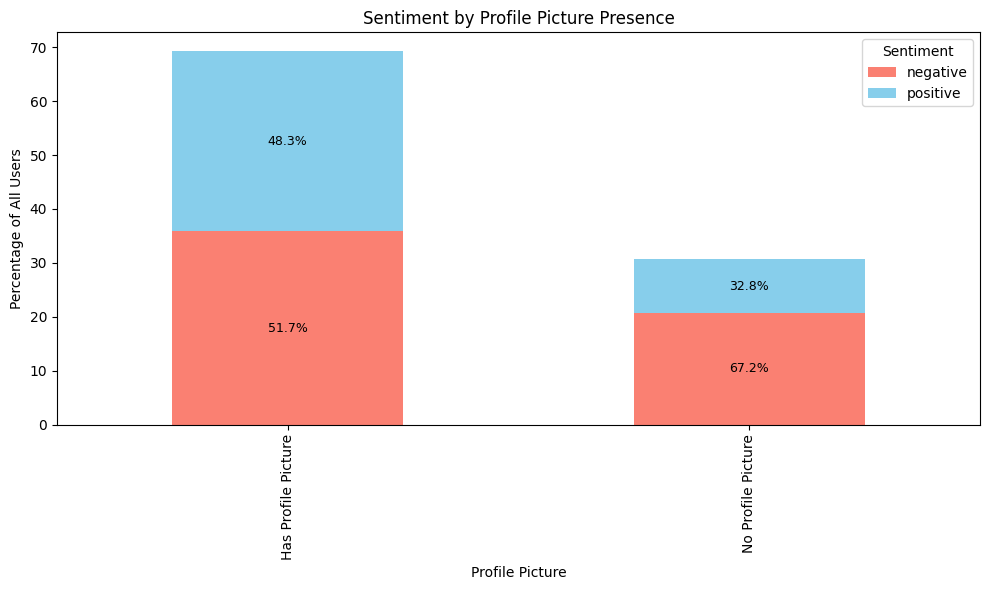

In [ ]:
# Map binary values to readable labels
df['picture_label'] = df['has_profile_picture'].map({0: 'No Profile Picture', 1: 'Has Profile Picture'})

# Sentiment counts and normalization
pic_bin = pd.crosstab(df['picture_label'], df['sentiment'])
group_totals = pic_bin.sum(axis=1)
share_of_total = group_totals / group_totals.sum()
within_group_pct = pic_bin.div(group_totals, axis=0)
final_vals = within_group_pct.mul(share_of_total, axis=0) * 100

# Plot
ax = final_vals.plot(kind='bar', stacked=True, color=['salmon', 'skyblue'],
                     figsize=(10,6), title='Sentiment by Profile Picture Presence')

plt.xlabel('Profile Picture')
plt.ylabel('Percentage of All Users')
plt.legend(title='Sentiment')
plt.tight_layout()

# Add sentiment % labels within each bar
for i, group in enumerate(final_vals.index):
    pos = within_group_pct.loc[group, 'positive'] * 100
    neg = within_group_pct.loc[group, 'negative'] * 100
    neg_rect, pos_rect = ax.containers[0][i], ax.containers[1][i]

    ax.text(neg_rect.get_x() + neg_rect.get_width()/2,
            neg_rect.get_y() + neg_rect.get_height()/2,
            f'{neg:.1f}%', ha='center', va='center', fontsize=9, color='black')
    ax.text(pos_rect.get_x() + pos_rect.get_width()/2,
            pos_rect.get_y() + pos_rect.get_height()/2,
            f'{pos:.1f}%', ha='center', va='center', fontsize=9, color='black')

plt.show()


N-GRAM

In [ ]:
import re
from sklearn.feature_extraction.text import CountVectorizer

def clean(txt: str) -> str:
    txt = str(txt).lower()
    txt = re.sub(r'#\w+',  '', txt)              # drop hashtags
    txt = re.sub(r'http\S+|www\S+', '', txt)     # drop urls
    txt = re.sub(r'[^a-z\s]', '', txt)           # keep letters & spaces
    return txt.strip()

df['clean_text'] = df['text'].fillna('').apply(clean)

# ─────────────────────── 2.  BINARY N-GRAM MATRIX ─────────────────────
vec = CountVectorizer(
        ngram_range=(1, 2),          # unigrams + bigrams
        min_df=5, max_df=0.8,        # ignore too-rare / too-common
        stop_words='english'         # built-in stop-word list
      )

X_counts  = vec.fit_transform(df['clean_text'])      # raw counts (sparse)
X_binary  = (X_counts > 0).astype(np.int8)           # 0 / 1 indicator matrix
feature_names = vec.get_feature_names_out()          # if you need them later

print("Binary matrix shape:", X_binary.shape)


Binary matrix shape: (39473, 11116)


<ipython-input-22-dd14aacfda54>:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  positive['hashtags'].replace(r'^\s*$', pd.NA, regex=True, inplace=True)
<ipython-input-22-dd14aacfda54>:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value,

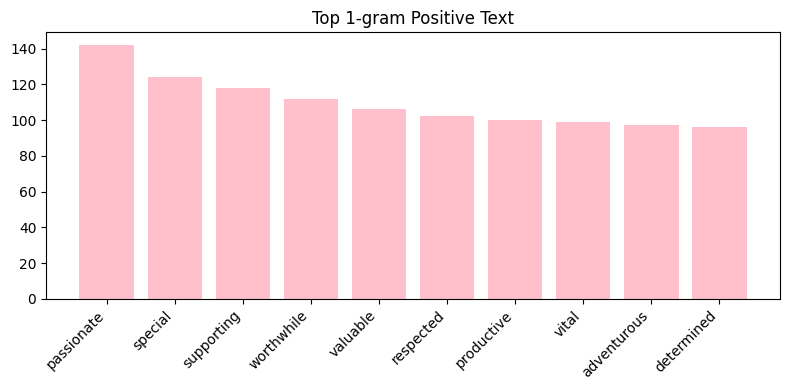

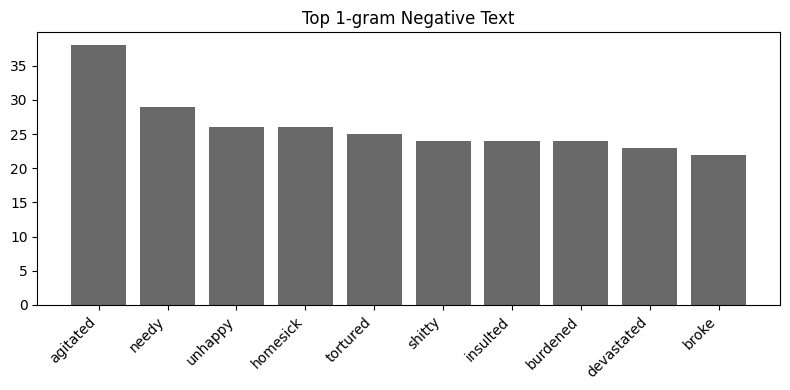

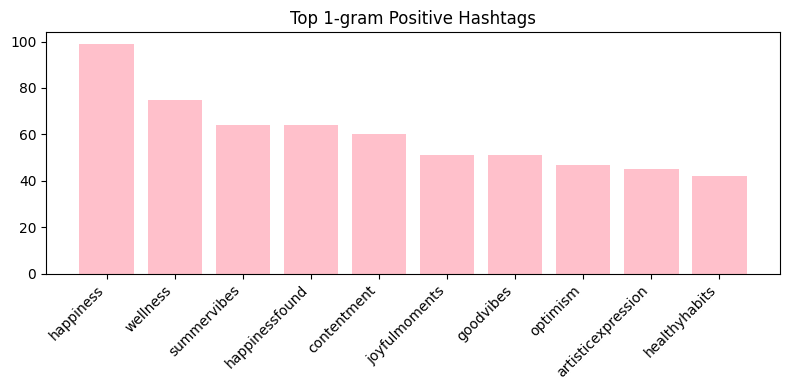

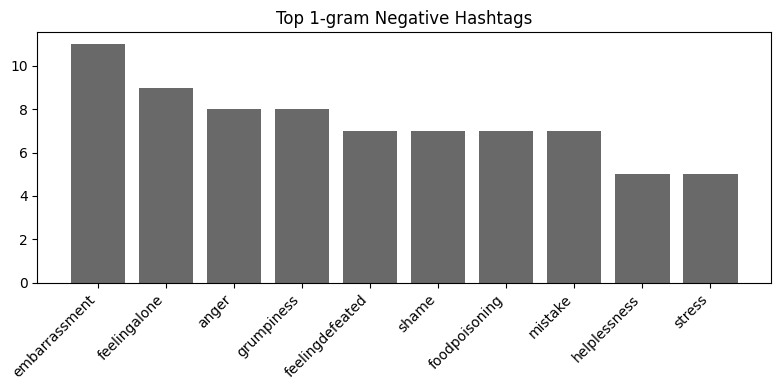

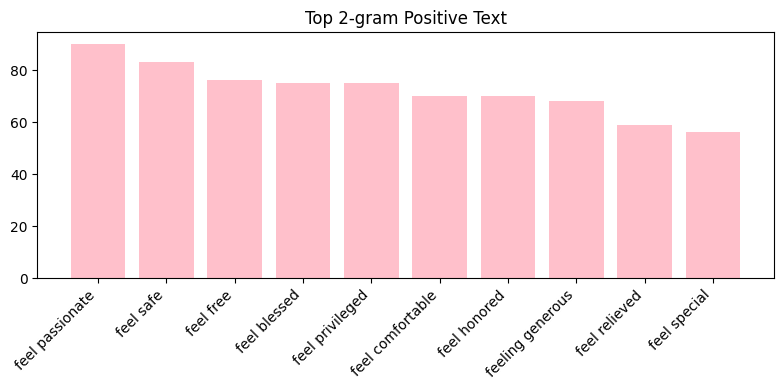

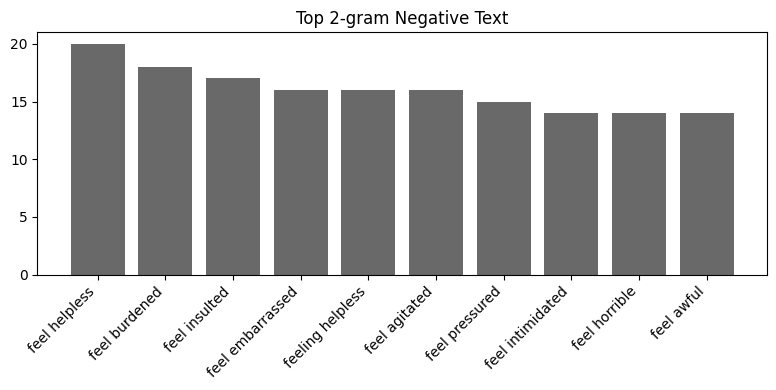

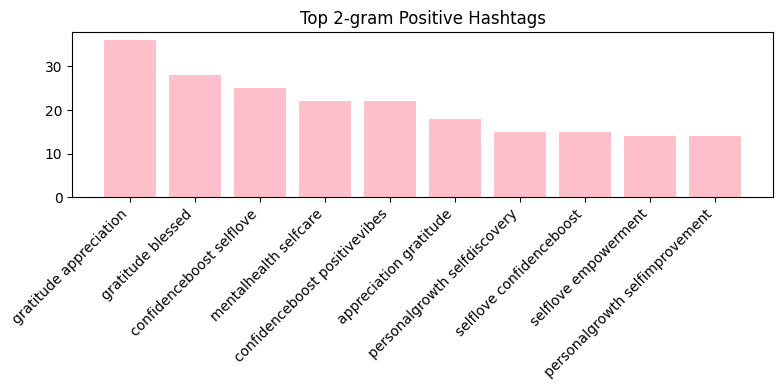

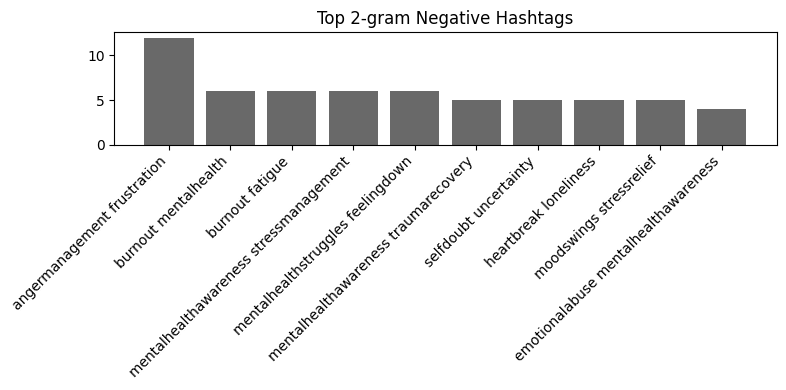

In [ ]:
# Extract hashtags and clean text
df['hashtags'] = df['text'].apply(lambda x: ' '.join(re.findall(r"#\w+", x)))
df['main_text'] = df['text'].apply(lambda x: re.sub(r"#\w+", "", x))

# Filter by sentiment
positive = df[df['sentiment'] == 'positive'].copy()
negative = df[df['sentiment'] == 'negative'].copy()

# Remove empty hashtags
positive['hashtags'].replace(r'^\s*$', pd.NA, regex=True, inplace=True)
negative['hashtags'].replace(r'^\s*$', pd.NA, regex=True, inplace=True)
positive.dropna(subset=['hashtags'], inplace=True)
negative.dropna(subset=['hashtags'], inplace=True)

# Function to get top n-grams
def get_top_ngrams(corpus, ngram_range=(1, 1), top_n=10):
    vec = CountVectorizer(ngram_range=ngram_range, stop_words='english')
    X = vec.fit_transform(corpus)
    sum_words = X.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    return sorted(words_freq, key=lambda x: x[1], reverse=True)

# Function to get unique n-grams
def ngram_analysis(pos_series, neg_series, n):
    try:
        pos_ngrams = get_top_ngrams(pos_series, ngram_range=(n, n))
        neg_ngrams = get_top_ngrams(neg_series, ngram_range=(n, n))
        pos_set = set([w for w, _ in pos_ngrams])
        neg_set = set([w for w, _ in neg_ngrams])
        unique_pos = [t for t in pos_ngrams if t[0] not in neg_set]
        unique_neg = [t for t in neg_ngrams if t[0] not in pos_set]
        return unique_pos[:10], unique_neg[:10]
    except ValueError:
        return [], []

# Function to plot n-grams with color option
def plot_ngrams(ngrams, title, color):
    if not ngrams:
        return
    words, freqs = zip(*ngrams)
    plt.figure(figsize=(8, 4))
    plt.bar(words, freqs, color=color)
    plt.title(title)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

# Run for n = 1 and 2
for n in [1, 2]:
    text_pos, text_neg = ngram_analysis(positive['main_text'], negative['main_text'], n)
    hashtag_pos, hashtag_neg = ngram_analysis(positive['hashtags'], negative['hashtags'], n)

    plot_ngrams(text_pos, f"Top {n}-gram Positive Text", color='pink')
    plot_ngrams(text_neg, f"Top {n}-gram Negative Text", color='dimgray')
    plot_ngrams(hashtag_pos, f"Top {n}-gram Positive Hashtags", color='pink')
    plot_ngrams(hashtag_neg, f"Top {n}-gram Negative Hashtags", color='dimgray')


Feature Representation

Catgorial Features


In [ ]:

# One-hot encode the age_group column to boolean columns
df_age_bools = pd.get_dummies(df['age_group'], prefix='age_group', dtype=int)


# One-hot encode 'day_period'
df_day_bools = pd.get_dummies(df['day_period'], prefix='day_period', dtype=int)

# One-hot encode 'checkmark'
df_checkmark_bools = pd.get_dummies(df['checkmark'], prefix='checkmark', dtype=int)

# Combine everything
df = pd.concat([df, df_age_bools, df_day_bools, df_checkmark_bools], axis=1)

print(df.head(2))

                                     id  \
0  2f2c6353-32b9-4432-b285-39ac9102bb03   
1  d61d3af4-e568-4a9d-8f16-b6ce98da2b60   

                                                text sentiment     type  \
0  i feel selfish when i send a chapter because i...  negative     post   
1  i couldnt help feeling like this scene was goi...  positive  retweet   

        post_datetime timezone  post_likes  posts_retweets  \
0 2025-08-21 20:35:00     AEST        63.0            31.0   
1 2021-10-13 10:04:00      EET        53.0             2.0   

                                embedded_content_url    username  ...  \
0  https://assets.storage.net/1dacdb5c-dbae-4982-...   @user6423  ...   
1                                                NaN  @brian_han  ...   

  day_period_Afternoon day_period_Early Morning day_period_Evening  \
0                    0                        0                  1   
1                    0                        0                  0   

  day_period_Midday  day_p

In [ ]:
df.isna().mean() * 100

,0
id,0.000000
text,0.000000
sentiment,0.000000
type,0.000000
post_datetime,0.000000
timezone,0.000000
post_likes,0.000000
posts_retweets,0.000000
embedded_content_url,76.875333
username,0.000000


Numeric Features

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Extract hashtags
df['hashtags'] = df['text'].str.findall(r'#\w+').apply(lambda x: x if isinstance(x, list) else [])

# Count number of hashtags
df['hashtag_count'] = df['hashtags'].apply(len)

# Numeric columns
numeric_cols = ['followers', 'posts_retweets', 'previous_posts_count', 'years_on_platform', 'hashtag_count']

# Normalize
scaler = MinMaxScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df[numeric_cols]), columns=numeric_cols)

# 🔐 Reset indices to avoid misalignment
df.reset_index(drop=True, inplace=True)
df_scaled.reset_index(drop=True, inplace=True)

# Merge safely
df = pd.concat([df, df_scaled.add_suffix('_scaled')], axis=1)

# Confirm text is still full
print(df[['text'] + [col + '_scaled' for col in numeric_cols]].head())


                                                text  followers_scaled  \
0  i feel selfish when i send a chapter because i...          0.003024   
1  i couldnt help feeling like this scene was goi...          0.000265   
2  i liked it for its free feeling and i really l...          0.000389   
3  i retreat ended i woke up feeling extremely ag...          0.000108   
4  i have been thinking hard about all that feeli...          0.000978   

   posts_retweets_scaled  previous_posts_count_scaled  \
0               0.001859                     0.212077   
1               0.000120                     0.000000   
2               0.000240                     0.132548   
3               0.000240                     0.000000   
4               0.000839                     0.072165   

   years_on_platform_scaled  hashtag_count_scaled  
0                  0.428571              0.000000  
1                  0.190476              0.000000  
2                  0.380952              0.000000  
3   

Text - TF-IDF

In [ ]:

import re

import matplotlib.cm as cm
from sklearn.feature_extraction.text import TfidfVectorizer
from collections import Counter

#Clean and prepare text (remove hashtags)
def clean(text):
    text = str(text).lower()
    text = re.sub(r'#\w+', '', text)             # remove hashtags
    text = re.sub(r'http\S+|www\S+', '', text)   # remove URLs
    text = re.sub(r'[^a-z\s]', '', text)         # remove punctuation
    return text.strip()

df['clean_text'] = df['text'].apply(clean)

#Split by sentiment
pos_texts = df[df['sentiment'] == 'positive']['clean_text']
neg_texts = df[df['sentiment'] == 'negative']['clean_text']

#Fit vectorizer on all text
vectorizer = TfidfVectorizer(stop_words='english', max_features=10_000)
vectorizer.fit(df['clean_text'])

# Save the fitted vectorizer for reuse
import joblib
joblib.dump(vectorizer, 'tfidf_vectorizer.pkl')


print(hasattr(vectorizer, 'idf_'))
#Transform
tfidf_pos = vectorizer.transform(pos_texts)
tfidf_neg = vectorizer.transform(neg_texts)

#Get top-N TF-IDF terms
def get_top_terms(tfidf_mat, vectorizer, N=50):
    scores = np.asarray(tfidf_mat.sum(axis=0)).ravel()
    terms = vectorizer.get_feature_names_out()
    sorted_idx = scores.argsort()[::-1][:N*2]  # get more to filter shared
    return [(terms[i], scores[i]) for i in sorted_idx]

top_pos = get_top_terms(tfidf_pos, vectorizer)
top_neg = get_top_terms(tfidf_neg, vectorizer)

#Remove shared terms
pos_words = set([t[0] for t in top_pos])
neg_words = set([t[0] for t in top_neg])
shared = pos_words & neg_words

unique_pos = [(t, s) for t, s in top_pos if t not in shared][:50]
unique_neg = [(t, s) for t, s in top_neg if t not in shared][:50]

#Unpack
pos_labels, pos_scores = zip(*unique_pos)
neg_labels, neg_scores = zip(*unique_neg)

print(unique_pos)
print(unique_neg)



True
[('happy', np.float64(133.91300711922113)), ('blessed', np.float64(128.5219284112087)), ('passionate', np.float64(111.45570003103343)), ('accepted', np.float64(110.30478017014248)), ('sweet', np.float64(108.4193032950055)), ('better', np.float64(97.51236729227254)), ('loved', np.float64(96.4239320450992)), ('sure', np.float64(95.64966206661585)), ('generous', np.float64(90.26280022149054)), ('thankful', np.float64(89.31752617599568)), ('important', np.float64(88.51074075455602)), ('supporting', np.float64(87.26504449016744)), ('excited', np.float64(83.7471239574449)), ('positive', np.float64(82.7783590867576)), ('href', np.float64(79.81544169532941)), ('confident', np.float64(78.14854393486567)), ('wonderful', np.float64(76.96685006795686)), ('comfortable', np.float64(76.64607585294847)), ('productive', np.float64(75.06016971678395)), ('proud', np.float64(74.6043561729675)), ('special', np.float64(74.18169073033172)), ('amazing', np.float64(73.82266649441407)), ('relieved', np.flo

In [ ]:
vectorizer2 = joblib.load('tfidf_vectorizer.pkl')
print(hasattr(vectorizer2, 'idf_'))  # should be True


True


In [ ]:
# 1)  duplicate column names?
dupe_cols = df.columns[df.columns.duplicated()]
print("Duplicate column names:", dupe_cols.tolist())

# 2)  duplicate row labels?
dupe_rows = df.index[df.index.duplicated()]
print("Number of duplicate row-index labels:", len(dupe_rows))


Duplicate column names: []
Number of duplicate row-index labels: 0


In [ ]:
from sklearn.preprocessing import MinMaxScaler
# reate rank dictionaries
pos_rank = {word: i + 1 for i, (word, _) in enumerate(unique_pos)}
neg_rank = {word: i + 1 for i, (word, _) in enumerate(unique_neg)}

# Tokenization and scoring
def tokenize(text):
    return re.findall(r'\b\w+\b', str(text).lower())

def score_text(text, word_rank):
    words = tokenize(text)
    return sum(word_rank.get(w, 0) for w in words)

# Ensure scores are numeric and no NaNs
df['pos_score'] = df['clean_text'].apply(lambda x: score_text(x, pos_rank)).astype(float)
df['neg_score'] = df['clean_text'].apply(lambda x: score_text(x, neg_rank)).astype(float)

# Fill any missing scores with 0
df[['pos_score', 'neg_score']] = df[['pos_score', 'neg_score']].fillna(0)

# Convert to dense array before scaling
scaler = MinMaxScaler()
scaled_values = scaler.fit_transform(df[['pos_score', 'neg_score']].values)

joblib.dump(scaler, 'scaler.pkl')  # 💾 Save the fitted scaler


# Assign scaled values back
df['pos_score_scaled'] = scaled_values[:, 0]
df['neg_score_scaled'] = scaled_values[:, 1]

# Check result
print(df[['text', 'pos_score', 'neg_score', 'pos_score_scaled', 'neg_score_scaled']].head())


                                                text  pos_score  neg_score  \
0  i feel selfish when i send a chapter because i...        0.0       18.0   
1  i couldnt help feeling like this scene was goi...       39.0        0.0   
2  i liked it for its free feeling and i really l...       93.0        0.0   
3  i retreat ended i woke up feeling extremely ag...        0.0       10.0   
4  i have been thinking hard about all that feeli...        0.0       20.0   

   pos_score_scaled  neg_score_scaled  
0          0.000000          0.065455  
1          0.236364          0.000000  
2          0.563636          0.000000  
3          0.000000          0.036364  
4          0.000000          0.072727  


Feature Selection

Fischer Score

In [ ]:
selected_features = [
    # Numeric
    'followers_scaled', 'posts_retweets_scaled', 'previous_posts_count_scaled',
    'years_on_platform_scaled', 'hashtag_count_scaled',
    'pos_score_scaled', 'neg_score_scaled',

    # Binary
    'has_profile_pic',

    # Categorical (one-hot encoded)
    'checkmark_blue', 'checkmark_gold', 'checkmark_grey', 'checkmark_none',
    'day_period_Early Morning', 'day_period_Morning', 'day_period_Midday', 'day_period_Afternoon','day_period_Evening', 'day_period_Night',
    'age_group_<18', 'age_group_18–24', 'age_group_25–34', 'age_group_35–44', 'age_group_45–54', 'age_group_55–64', 'age_group_65+'
]

def fischer_score(feature_values, labels):
    # Convert both to NumPy arrays to avoid Series index issues
    feature_values = np.array(feature_values)
    labels = np.array(labels)

    pos = feature_values[labels == 'positive']
    neg = feature_values[labels == 'negative']

    mean_diff = np.abs(pos.mean() - neg.mean())
    std_sum = pos.std() + neg.std()

    return 0 if std_sum == 0 else mean_diff / std_sum



def calculate_fischer_scores(df, feature_list, label_col='sentiment'):
    labels = df[label_col]
    scores = {
        col: fischer_score(df[col], labels) for col in feature_list
    }
    return pd.DataFrame(scores.items(), columns=['feature', 'fisher_score'])\
             .sort_values(by='fisher_score', ascending=False).reset_index(drop=True)

fisher_df = calculate_fischer_scores(df, selected_features, label_col='sentiment')
print(fisher_df)


                        feature  fisher_score
0          hashtag_count_scaled      0.552902
1              pos_score_scaled      0.370600
2   previous_posts_count_scaled      0.318618
3              neg_score_scaled      0.234658
4                checkmark_gold      0.228167
5                checkmark_grey      0.227354
6                checkmark_none      0.195385
7               has_profile_pic      0.148635
8            day_period_Morning      0.120930
9               age_group_18–24      0.112518
10             followers_scaled      0.106779
11        posts_retweets_scaled      0.103967
12           day_period_Evening      0.096299
13                age_group_<18      0.089308
14             day_period_Night      0.067222
15               checkmark_blue      0.061164
16              age_group_35–44      0.052302
17            day_period_Midday      0.049203
18     day_period_Early Morning      0.047267
19         day_period_Afternoon      0.042221
20              age_group_25–34   

Correlation Feature Selection

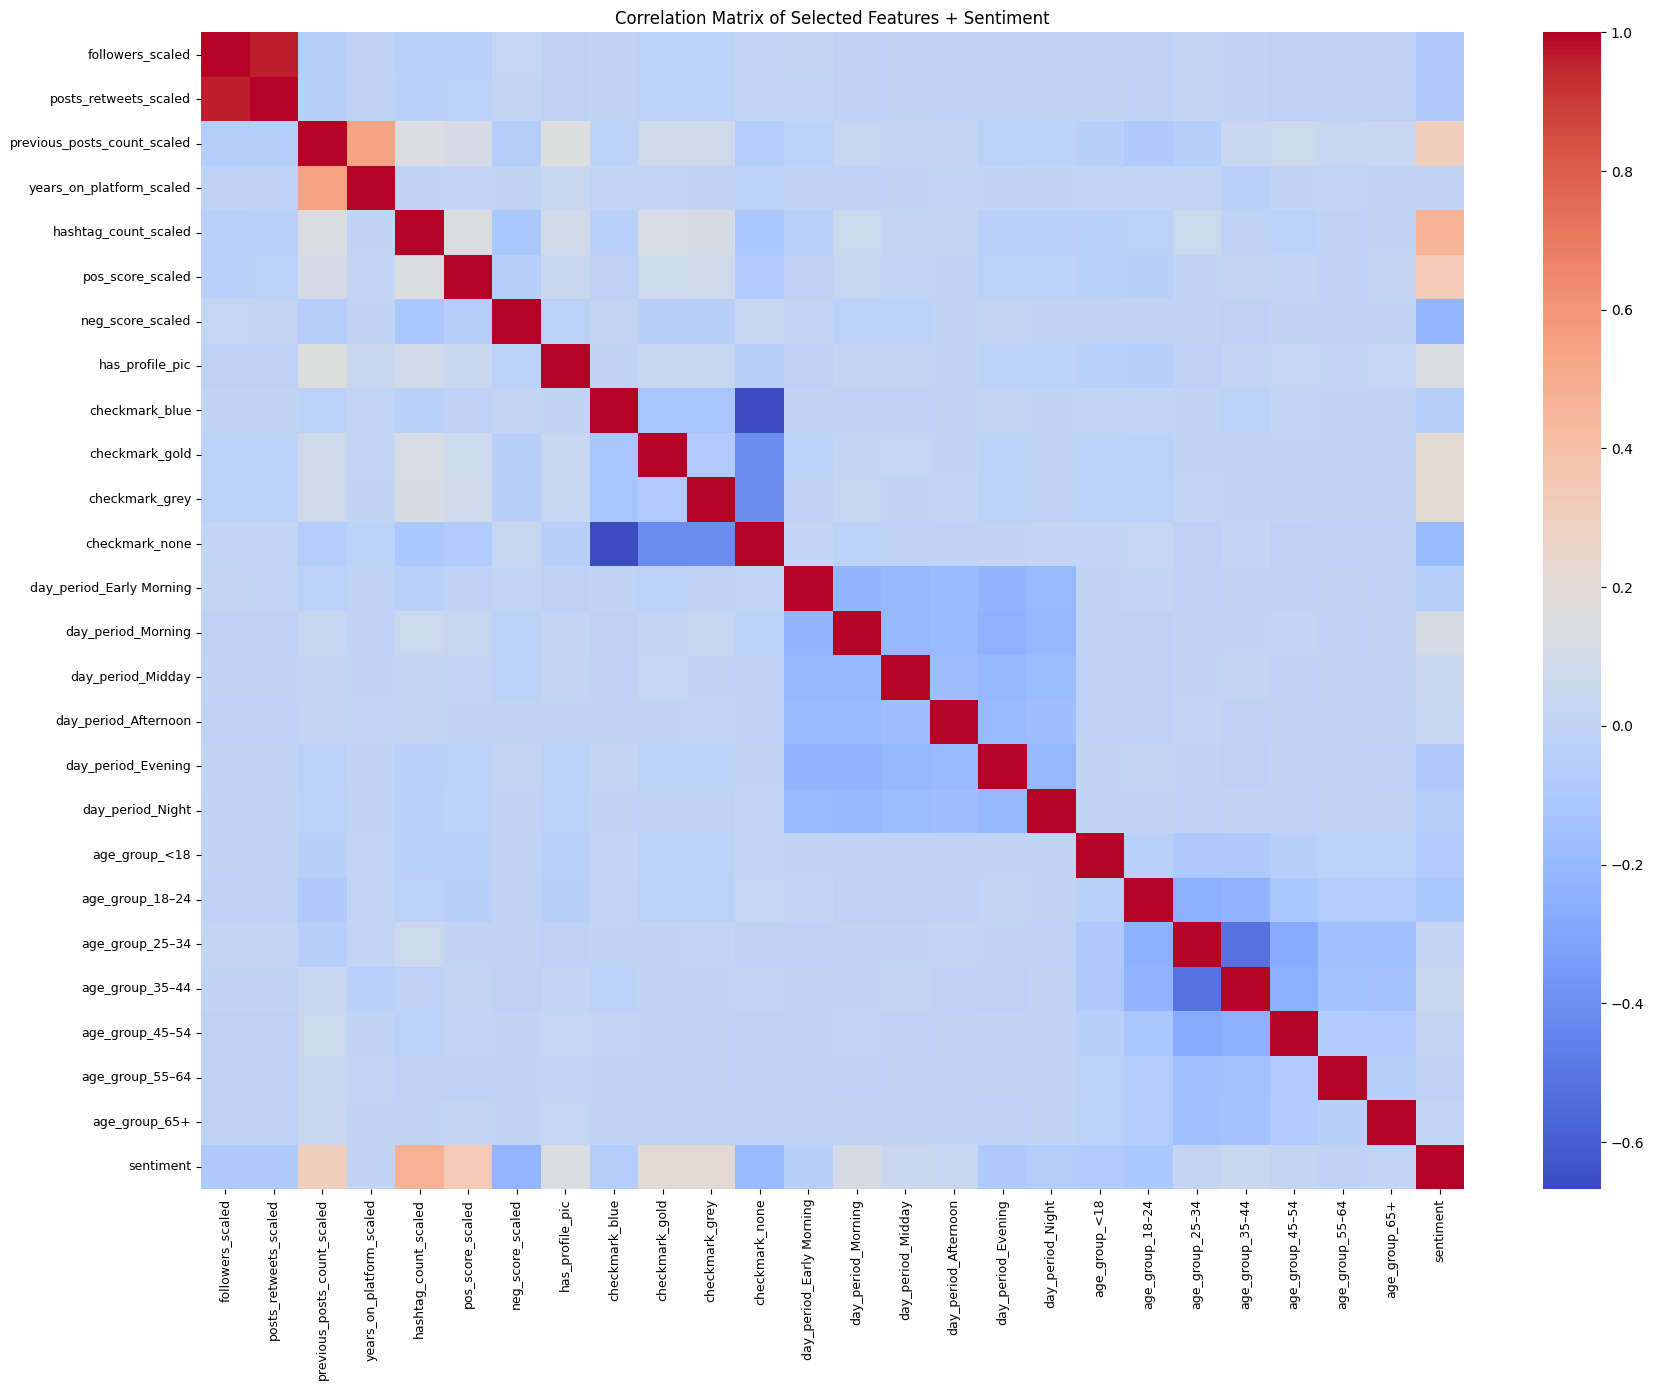


Mutual Information Scores:

                        feature  mutual_info
0          hashtag_count_scaled     0.129442
1              pos_score_scaled     0.121535
2   previous_posts_count_scaled     0.084430
3              followers_scaled     0.068507
4              neg_score_scaled     0.057747
5         posts_retweets_scaled     0.056511
6                checkmark_none     0.025743
7                checkmark_grey     0.022542
8                checkmark_gold     0.022163
9               has_profile_pic     0.016815
10           day_period_Morning     0.011199
11           day_period_Evening     0.008487
12                age_group_<18     0.007342
13              age_group_18–24     0.006164
14              age_group_55–64     0.004179
15             day_period_Night     0.003772
16              age_group_25–34     0.003141
17               checkmark_blue     0.002611
18                age_group_65+     0.001903
19              age_group_35–44     0.001690
20         day_period_Afte

In [ ]:
from sklearn.feature_selection import mutual_info_classif
import seaborn as sns

# === 1. Select relevant features ===
selected_features = [
    'followers_scaled', 'posts_retweets_scaled', 'previous_posts_count_scaled',
    'years_on_platform_scaled', 'hashtag_count_scaled',
    'pos_score_scaled', 'neg_score_scaled',

    # Binary
    'has_profile_pic',

    # Categorical (one-hot encoded)
    'checkmark_blue', 'checkmark_gold', 'checkmark_grey', 'checkmark_none',
    'day_period_Early Morning', 'day_period_Morning', 'day_period_Midday', 'day_period_Afternoon',
    'day_period_Evening', 'day_period_Night',
    'age_group_<18', 'age_group_18–24', 'age_group_25–34', 'age_group_35–44',
    'age_group_45–54', 'age_group_55–64', 'age_group_65+'
]

# === 2. Prepare Data ===
X = df[selected_features].copy()
X['sentiment'] = df['sentiment'].apply(lambda x: 1 if x == 'positive' else 0)  # convert to 0/1
y = X['sentiment']  # target

# === 3. Correlation Matrix ===
corr_matrix = X.corr()

plt.figure(figsize=(18, 14))  # larger size
sns.heatmap(corr_matrix, cmap='coolwarm', cbar=True)

plt.xticks(ticks=np.arange(len(corr_matrix.columns)) + 0.5,
           labels=corr_matrix.columns, rotation=90, ha='center', fontsize=9)
plt.yticks(ticks=np.arange(len(corr_matrix.index)) + 0.5,
           labels=corr_matrix.index, rotation=0, fontsize=9)

plt.title("Correlation Matrix of Selected Features + Sentiment")
plt.tight_layout()
plt.show()

# === 4. Mutual Information (Gain Ratio Approximation) ===
mi_scores = mutual_info_classif(X.drop(columns='sentiment'), y, discrete_features='auto', random_state=42)
mi_df = pd.DataFrame({'feature': X.drop(columns='sentiment').columns, 'mutual_info': mi_scores})
mi_df = mi_df.sort_values(by='mutual_info', ascending=False).reset_index(drop=True)

# === 5. Display result ===
print("\nMutual Information Scores:\n")
print(mi_df)
# === 6. Top features correlated with sentiment ===
sentiment_corr = corr_matrix['sentiment'].drop('sentiment')  # remove self-correlation
sentiment_corr_df = sentiment_corr.abs().sort_values(ascending=False).to_frame(name='abs_corr_with_sentiment')
sentiment_corr_df['actual_corr'] = sentiment_corr.loc[sentiment_corr_df.index]  # add signed value

print("\nTop features correlated with sentiment:\n")
print(sentiment_corr_df.head(10))  # Show top 10



Dimensionality Reduction

PCA

Cumulative explained variance (300 components): 43.72%
First 10 component variances: [0.0177 0.0442 0.0208 0.0143 0.0104 0.0085 0.0063 0.0058 0.0051 0.005 ]


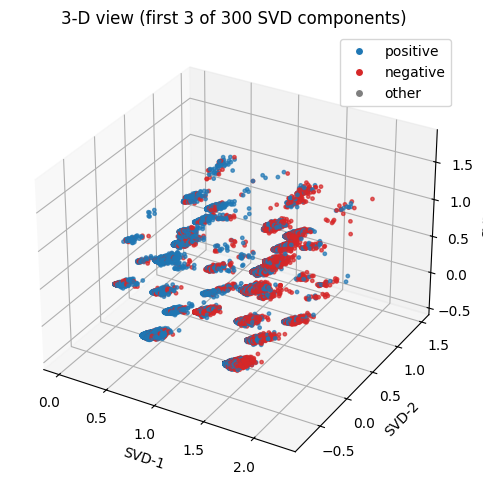

In [ ]:

from sklearn.decomposition import TruncatedSVD
from mpl_toolkits.mplot3d import Axes3D   # noqa: needed for 3‑D projection

# ------------------------------------------------------------------
# 1. Fit Truncated SVD on the sparse n‑gram matrix
# ------------------------------------------------------------------
n_components = 300                        # choose how many to keep
svd = TruncatedSVD(n_components=n_components, random_state=42)
X_svd = svd.fit_transform(X_binary)       # dense (n_samples × n_components)

# ------------------------------------------------------------------
# 2. Inspect explained variance
# ------------------------------------------------------------------
cum_var = svd.explained_variance_ratio_.sum()
print(f"Cumulative explained variance "
      f"({n_components} components): {cum_var:.2%}")

print("First 10 component variances:",
      np.round(svd.explained_variance_ratio_[:10], 4))

# ------------------------------------------------------------------
# 3. 3‑D scatter of the first three components
# ------------------------------------------------------------------
if n_components < 3:
    raise ValueError("Need at least 3 components for a 3‑D plot")

X_3d = X_svd[:, :3]

# Build colour array (positive / negative / other)
sent_map = {'positive': 'tab:blue', 'negative': 'tab:red'}
colors = (df['sentiment'].astype(str)
          .map(sent_map)
          .fillna('tab:gray')
          .to_numpy()) if 'sentiment' in df.columns else np.full(len(df), 'tab:gray')

fig = plt.figure(figsize=(7, 5))
ax  = fig.add_subplot(111, projection='3d')

ax.scatter(X_3d[:, 0], X_3d[:, 1], X_3d[:, 2],
           c=colors, s=6, alpha=0.7)

if 'sentiment' in df.columns:
    ax.legend(handles=[
        plt.Line2D([0], [0], marker='o', color='w',
                   markerfacecolor='tab:blue', markersize=6, label='positive'),
        plt.Line2D([0], [0], marker='o', color='w',
                   markerfacecolor='tab:red',  markersize=6, label='negative'),
        plt.Line2D([0], [0], marker='o', color='w',
                   markerfacecolor='tab:gray', markersize=6, label='other')
    ], loc='best')

ax.set_xlabel('SVD‑1')
ax.set_ylabel('SVD‑2')
ax.set_zlabel('SVD‑3')
ax.set_title(f'3‑D view (first 3 of {n_components} SVD components)')

plt.tight_layout()
plt.show()


In [ ]:
print(X_svd.shape)          # e.g.  (39_473, 300)
print(X_svd[:3, :5])        # first 3 posts, first 5 components


(39473, 300)
[[ 1.43428568 -0.05245039 -0.1678896   0.52618101 -0.66511813]
 [ 1.11599784  0.94951004  0.62476814 -0.56521948  0.24566373]
 [ 0.98362726  1.03876431 -0.10935485 -0.22116147  0.30462198]]


In [ ]:
from sklearn.preprocessing import MinMaxScaler
#Normalization
scaler = MinMaxScaler()
X_svd_scaled = scaler.fit_transform(X_svd)     # same shape, values now in [0, 1]

print(X_svd_scaled[:3, :5])

#turn into a dataframe
svd_cols = [f'svd_{i+1}' for i in range(X_svd_scaled.shape[1])]
svd_df = pd.DataFrame(X_svd_scaled, columns=svd_cols, index=df.index)

selected_features = [
    'followers_scaled', 'posts_retweets_scaled', 'previous_posts_count_scaled', 'hashtag_count_scaled',
    'pos_score_scaled', 'neg_score_scaled',

    # Binary
    'has_profile_pic',

    # Categorical (one-hot encoded)
    'checkmark_blue', 'checkmark_gold', 'checkmark_grey', 'checkmark_none',
    'day_period_Early Morning', 'day_period_Morning', 'day_period_Midday', 'day_period_Afternoon',
    'day_period_Evening', 'day_period_Night',
    'age_group_<18', 'age_group_18–24', 'age_group_25–34', 'age_group_35–44',
    'age_group_45–54', 'age_group_55–64', 'age_group_65+'
]


df_model = pd.concat([df[selected_features], svd_df], axis=1)
y = df['sentiment']   # this should contain 'positive' or 'negative'
df_model.to_pickle('/content/df_model.pkl')

from google.colab import files
files.download('/content/df_model.pkl')

print(df_model.shape)

[[0.63984115 0.32268247 0.12039442 0.55096851 0.18778729]
 [0.49783303 0.76336661 0.48125975 0.10210566 0.59916562]
 [0.43877423 0.80262259 0.14704295 0.24360721 0.62579564]]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

(39473, 324)


In [ ]:
df.to_pickle('/content/df.pkl')
from google.colab import files
files.download('/content/df.pkl')
print(df.shape)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

(39473, 64)
